# Task 1 · A guided tour of quantum machine learning
### Detecting credit-card fraud with a variational quantum classifier, with and without noise

> **This is the exercise version.** Cells marked ✏️ contain blanks, marked `FILL_IN`, for you to fill in.

**Fraud on a Quantum Budget, guided notebook.** In the next few hours you will build, train, test and stress-test a quantum machine-learning model that flags fraudulent card payments. You start from a raw table of 284,807 transactions and end with a variational quantum classifier (VQC) running on a simulated *noisy* quantum computer, ready to be improved in Task 2.

**Who this is for.** You know the basics of quantum computing: qubits, the Bloch sphere, gates such as H, RY, RZ and CNOT, and measurement. You do **not** need any background in machine learning, PyTorch or PennyLane: every concept is introduced when it is first needed.

**What you will learn**
- the machine-learning workflow: data, features, labels, loss, training, validation, test;
- how to measure success when only 0.17% of the examples are positive: precision, recall, AUPRC;
- PennyLane: devices, QNodes, measurements, shots, gradients and the parameter-shift rule;
- how a VQC is put together (feature map, ansatz, readout) and trained with PyTorch;
- what training would cost on a real quantum computer;
- how noise changes a quantum model, and how to simulate and measure it in PennyLane.

The pipeline follows Dinuț, Constantinescu and Alexandrescu, *Comparative Analysis and Noise Robustness Study of Quantum Kernel Methods and Variational Quantum Classifiers for Financial Fraud Detection*, Electronics 15(11), 2489 (2026), [doi:10.3390/electronics15112489](https://doi.org/10.3390/electronics15112489). The article used Qiskit; here the same circuits are rebuilt in PennyLane, with PyTorch for training.

### How to use this notebook

| Marker | Meaning |
|---|---|
| ✏️ **Exercise** | Replace every `FILL_IN` with code. Hints are in the comments. |
| ✅ **Check** | Run the cell right after an exercise. A green tick means you can move on; otherwise the message says what is wrong. |
| 💡 **PennyLane shortcut** | A built-in PennyLane function that does what you just wrote by hand. Worth knowing for Task 2. |
| 📝 **Quiz checkpoint** | Time to answer a few questions of the quiz (`quiz_quantum_ml_fraud.pdf`). |
| 🔁 **Task 2 hook** | A place where a change could make the model better or cheaper in Task 2. |

- Run the cells **in order**, from top to bottom (Shift + Enter runs a cell). Later cells use variables defined by earlier ones. If something behaves strangely after you edited code, use *Kernel → Restart & Run All*.
- `NameError: name 'FILL_IN' is not defined` means that a blank is still waiting to be filled in.
- The whole notebook takes about 10 to 15 minutes of computer time on a laptop, most of it in Part 10 (noise). Reading it and doing the exercises takes about 4 hours.

### Roadmap

| Part | Topic | Time |
|---|---|---|
| 0 | Setup | 10 min |
| 1 | Machine learning in a nutshell, with PyTorch | 25 min |
| 2 | The dataset | 15 min |
| 3 | Measuring success when fraud is rare | 25 min |
| 4 | Split, balance, encode | 30 min |
| 5 | PennyLane crash course | 30 min |
| 6 | Building the variational quantum classifier | 30 min |
| 7 | Training | 15 min |
| 8 | What training would cost on a quantum computer | 15 min |
| 9 | Testing against a classical reference | 20 min |
| 10 | Noise | 45 min |
| 11 | Working with the dataset in Task 2, and the challenge | 15 min |

## Part 0 · Setup

**Installing.** You need Python 3.10 or newer and these packages:
```
pip install pennylane torch scikit-learn pandas matplotlib scipy
```
The notebook was tested with PennyLane 0.45, PyTorch 2.12 and scikit-learn 1.8. On Google Colab, run `!pip install pennylane` in a cell first (the other packages are already installed). The notebook also opens in VS Code with the Jupyter extension.

| Library | Used for |
|---|---|
| `numpy` | arrays of numbers and fast maths on them |
| `pandas` | tables: a `DataFrame` is a spreadsheet in Python |
| `matplotlib` | plots |
| `scikit-learn` (`sklearn`) | classical machine-learning tools: splitting data, scaling, PCA, metrics, logistic regression |
| `torch` (PyTorch) | tensors (arrays that remember how they were computed), automatic gradients, optimisers |
| `pennylane` (`qml`) | quantum circuits that PyTorch can differentiate and train |
| `scipy` | the Spearman rank correlation |

**Settings.** Every number that controls the pipeline is set once, in the next cell. `SEED` fixes all the random choices (the split, the sampling, the initial weights), so that a rerun gives exactly the same result. Reproducibility is a requirement of Task 2.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import torch
from scipy.stats import spearmanr
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

SEED = 42                     # master seed: split, first undersampling, first initialisation
SAMPLE_FRACTION = 1.0         # < 1.0 keeps a stratified fraction of the data, for fast experiments
N_QUBITS = 4                  # one PCA feature per qubit
FEATURE_MAP_REPS = 2          # repetitions of the ZZ feature map
ANSATZ_REPS = 3               # entangling layers of the ansatz: (ANSATZ_REPS + 1) * N_QUBITS * 2 parameters
EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.05
SHOTS_PER_EXECUTION = 1024    # only used for the hardware cost ledger
NOISE_LEVELS = [0.001, 0.01, 0.05]                                   # depolarizing probability per gate
NATIVE_GATES = {"RX", "RY", "RZ", "Rot", "Hadamard", "CNOT", "CZ"}   # gate set of the noise model (Part 10)
SEEDS = [0, 1, 2, 3, 4]

LEGIT_COLOR, FRAUD_COLOR = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)


def passed(exercise):
    print(f"✅ Exercise {exercise}: all checks passed.")


set_seed(SEED)
print("pennylane", qml.__version__, "| torch", torch.__version__)

pennylane 0.45.1 | torch 2.12.0+cpu


## Part 1 · Machine learning in a nutshell

**Supervised learning** is learning from examples whose answer is known. Each example is a pair $(x, y)$:
- $x$, the **features**: numbers that describe the example. Here one transaction is described by 30 numbers (time, amount and 28 anonymised quantities);
- $y$, the **label**: the answer we want to predict. Here $y = 1$ for fraud and $y = 0$ for a legitimate payment.

A **model** is a function $f_\theta(x)$ with adjustable numbers $\theta$, its **parameters** (also called weights). Our models output a **score** between 0 and 1, read as the estimated probability that the transaction is fraud. **Training** means choosing $\theta$ so that the scores agree with the labels on a set of examples, the **training set**.

What we really want is a model that works on transactions it has **never seen**: this is called **generalisation**. A model can memorise its training examples and still fail on new ones (**overfitting**), which is why we always keep labelled data aside to check it. Part 4 splits the data into three sets:

| Set | Used to | Analogy |
|---|---|---|
| training | fit the parameters $\theta$ | the exercises you practise on |
| validation | take decisions: which epoch to keep, which threshold, which architecture | the mock exam |
| test | measure the final performance, **once**, at the end | the real exam |

Choices that are not learned from the data but made by us (the number of layers, the learning rate, the number of epochs) are called **hyperparameters**; they are chosen with the validation set.

The simplest classifier for a 0/1 label is **logistic regression**: $f(x) = \sigma(w \cdot x + b)$, where $\sigma(z) = 1/(1+e^{-z})$, the *sigmoid*, squashes any number into $(0, 1)$. It has one weight per feature plus a bias $b$. We will use it as the classical reference for the quantum model.

### 1.1 The loss: how wrong is the model?

Training needs a single number that says how badly the model does: the **loss**. For 0/1 labels and probability-like scores $p_k = f_\theta(x_k)$ the standard choice is the **binary cross-entropy** (BCE), averaged over the $N$ examples:

$$L(\theta) = -\frac{1}{N}\sum_{k=1}^{N}\Big[\,y_k \log p_k + (1-y_k)\log(1-p_k)\Big].$$

For a fraud ($y=1$) only the first term survives: the loss is $-\log p$, which is $0.01$ for $p = 0.99$ but $4.6$ for $p = 0.01$. BCE barely punishes a confident right answer and heavily punishes a confident wrong one, as the plot shows.

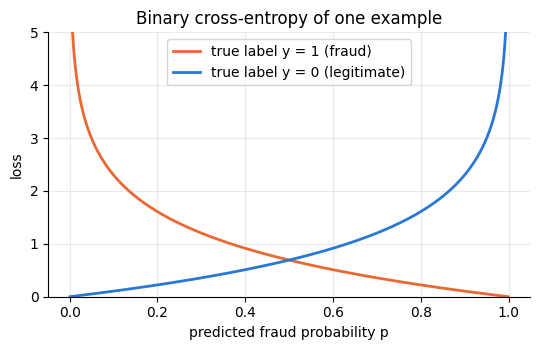

In [ ]:
p = np.linspace(0.001, 0.999, 500)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(p, -np.log(p), color=FRAUD_COLOR, linewidth=2, label="true label y = 1 (fraud)")
ax.plot(p, -np.log(1 - p), color=LEGIT_COLOR, linewidth=2, label="true label y = 0 (legitimate)")
ax.set_xlabel("predicted fraud probability p")
ax.set_ylabel("loss")
ax.set_ylim(0, 5)
ax.set_title("Binary cross-entropy of one example")
ax.legend()
plt.tight_layout()
plt.show()

✏️ **Exercise 1.1: binary cross-entropy.** Implement the formula above with PyTorch. `p` and `y` are tensors of the same length; `torch.log` is the natural logarithm and `.mean()` averages a tensor.

In [4]:
def binary_cross_entropy(p, y):
    '''Mean binary cross-entropy between predicted probabilities p and 0/1 labels y.'''
    loss = -(y * torch.log(p) + (1 - y) * torch.log(1 - p))
    return loss.mean()   

In [5]:
# ✅ Check 1.1: compare with PyTorch's own implementation
p_demo = torch.tensor([0.9, 0.2, 0.6, 0.01], dtype=torch.float64)
y_demo = torch.tensor([1.0, 0.0, 1.0, 0.0], dtype=torch.float64)
reference = torch.nn.BCELoss()(p_demo, y_demo)
assert torch.isclose(binary_cross_entropy(p_demo, y_demo), reference), f"expected {reference.item():.6f}"
passed("1.1")

✅ Exercise 1.1: all checks passed.


### 1.2 Gradient descent and automatic differentiation

How do we find parameters with a small loss? The **gradient** $\nabla_\theta L$ is the vector of partial derivatives $\partial L/\partial\theta_j$; it points in the direction in which the loss grows fastest. **Gradient descent** takes small steps the other way:

$$\theta \leftarrow \theta - \eta\,\nabla_\theta L(\theta),$$

where $\eta$, the **learning rate**, sets the step size. Too small and training crawls; too large and it overshoots and oscillates.

Computing gradients by hand would be painful. **PyTorch does it automatically** (*autograd*): a tensor created with `requires_grad=True` remembers the operations applied to it, and calling `.backward()` on the final number fills in the `.grad` attribute of every such tensor. PennyLane plugs into the same mechanism, so later the gradient of the loss with respect to the angles of a quantum circuit is computed in exactly the same way.

✏️ **Exercise 1.2: gradient descent by hand.** Minimise the toy loss $L(\theta) = (\theta - 3)^2$, whose minimum is at $\theta = 3$. Fill in the update step.

In [6]:
theta = torch.tensor(0.0, requires_grad=True)
lr = 0.1
for step in range(50):
    loss = (theta - 3.0) ** 2
    loss.backward()              # computes d loss / d theta and stores it in theta.grad
    with torch.no_grad():        # the update itself must not be recorded by autograd
        theta -= lr * theta.grad    # one gradient-descent step: learning rate times gradient
    theta.grad.zero_()           # PyTorch adds up gradients, so reset them after every step
print(f"theta after 50 steps: {theta.item():.5f}")

theta after 50 steps: 2.99996


In [7]:
# ✅ Check 1.2
assert abs(theta.item() - 3.0) < 1e-3, "theta should end very close to 3: check the sign and the size of the step"
passed("1.2")

✅ Exercise 1.2: all checks passed.


In practice the update is delegated to an **optimiser**. Every training loop in this notebook, and in most of deep learning, repeats the same four lines:

```python
optimizer.zero_grad()   # 1. forget the gradients of the previous step
loss = ...              # 2. compute the loss on a batch of examples
loss.backward()         # 3. compute the gradients
optimizer.step()        # 4. update the parameters
```

We use **Adam**, a variant of gradient descent that adapts the step size of each parameter using running averages of its past gradients (Kingma and Ba, 2015, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)). It is the default choice in most projects because it needs little tuning.

In [8]:
theta = torch.nn.Parameter(torch.tensor(0.0))   # a Parameter is a tensor that an optimiser may update
optimizer = torch.optim.Adam([theta], lr=0.1)
for step in range(200):
    optimizer.zero_grad()
    loss = (theta - 3.0) ** 2
    loss.backward()
    optimizer.step()
print(f"Adam after 200 steps: theta = {theta.item():.4f}")

Adam after 200 steps: theta = 3.0001


Two more words you will meet in Part 7:
- an **epoch** is one full pass over the training set;
- a **mini-batch** is a small group of examples (here 32) on which one gradient step is computed. Mini-batches make each step cheaper than using the whole training set, and their slight randomness often helps training.

📝 **Quiz checkpoint A**: questions 1 to 5.

## Part 2 · The dataset

The **ULB Credit Card Fraud** dataset (Machine Learning Group, Université Libre de Bruxelles; Dal Pozzolo et al., 2015, [doi:10.1109/SSCI.2015.33](https://doi.org/10.1109/SSCI.2015.33)) contains 284,807 card transactions made by European cardholders over two days in September 2013. 492 of them are fraudulent.

| Column | Meaning |
|---|---|
| `Time` | seconds elapsed since the first transaction of the dataset |
| `V1` … `V28` | 28 anonymised features: principal components (see Part 4) of confidential original features, released by the bank |
| `Amount` | transaction amount in euros |
| `Class` | the label: 1 = fraud, 0 = legitimate |

The next cell reads `data/creditcard.csv` (the [Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) file) if you have it, and otherwise downloads the identical copy from [OpenML](https://www.openml.org/d/42175) (dataset 42175, about 70 MB, cached after the first run). Do not use OpenML dataset 1597: it has the same rows but no `Time` column.

In [19]:
    DATA_PATH = Path("data/creditcard.csv/creditcard.csv")
    if DATA_PATH.exists():
        df = pd.read_csv(DATA_PATH)
    else:
        from sklearn.datasets import fetch_openml
        df = fetch_openml(data_id=42175, as_frame=True, parser="auto").frame

In [20]:
df[["Time", "V1", "V2", "V3", "Amount"]].describe().round(2)

,Time,V1,V2,V3,Amount
count,284807.00,284807.00,284807.00,284807.00,284807.00
mean,94813.86,0.00,0.00,-0.00,88.35
std,47488.15,1.96,1.65,1.52,250.12
min,0.00,-56.41,-72.72,-48.33,0.00
25%,54201.50,-0.92,-0.60,-0.89,5.60
50%,84692.00,0.02,0.07,0.18,22.00
75%,139320.50,1.32,0.80,1.03,77.16
max,172792.00,2.45,22.06,9.38,25691.16


Each row is one transaction, each column one feature. `describe()` summarises a few columns: `Amount` goes from 0 to more than 25,000 euros and `Time` up to 172,792 seconds, while `V1`–`V28` are centred around 0. The features live on very different scales, which matters in Part 4.

### 2.1 How rare is fraud?

✏️ **Exercise 2.1.** Count the frauds and the legitimate transactions, compute the fraud rate, and compute the **accuracy** (the fraction of correct answers) of a "model" that answers *legitimate* for every transaction.

In [21]:
# Hint: df["Class"] == 1 is a column of True/False values; .sum() counts the True ones.
n_fraud = (df["Class"] == 1).sum()               # number of rows with Class == 1
n_legit = (df["Class"] == 0).sum()                # number of rows with Class == 0
fraud_rate = n_fraud / len(df)                     # fraction of the transactions that are fraud
always_legit_accuracy = n_legit / len(df)          # fraction of correct answers when every transaction is called legitimate
print(f"legitimate: {n_legit:,}   fraud: {n_fraud:,}   fraud rate: {fraud_rate:.3%}")
print(f"accuracy of a model that always answers 'legitimate': {always_legit_accuracy:.2%}")

legitimate: 284,315   fraud: 492   fraud rate: 0.173%
accuracy of a model that always answers 'legitimate': 99.83%


✅ Exercise 2.1: all checks passed.


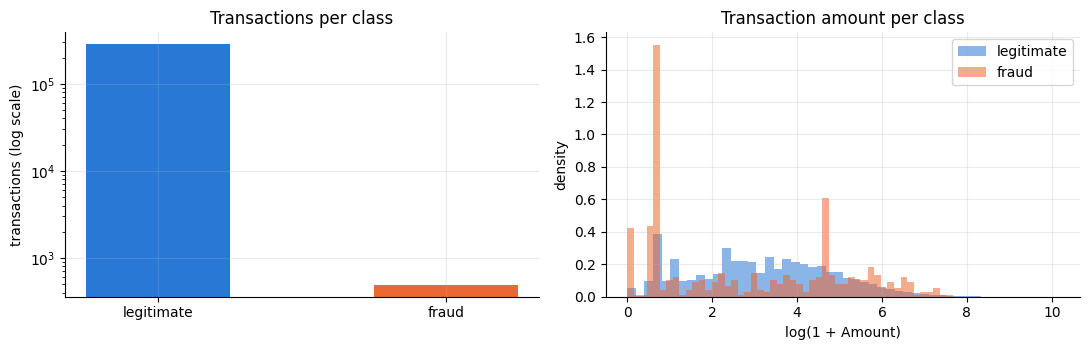

In [22]:
# ✅ Check 2.1
assert (n_fraud, n_legit) == (492, 284315), "count the rows of each class in the full dataset"
assert np.isclose(fraud_rate, 492 / 284807) and np.isclose(always_legit_accuracy, 284315 / 284807)
passed("2.1")

counts = df["Class"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(["legitimate", "fraud"], counts.values, color=[LEGIT_COLOR, FRAUD_COLOR], width=0.5)
axes[0].set_yscale("log")
axes[0].set_ylabel("transactions (log scale)")
axes[0].set_title("Transactions per class")
for label, name, color in [(0, "legitimate", LEGIT_COLOR), (1, "fraud", FRAUD_COLOR)]:
    amounts = np.log1p(df.loc[df["Class"] == label, "Amount"])
    axes[1].hist(amounts, bins=50, density=True, alpha=0.55, color=color, label=name)
axes[1].set_xlabel("log(1 + Amount)")
axes[1].set_ylabel("density")
axes[1].set_title("Transaction amount per class")
axes[1].legend()
plt.tight_layout()
plt.show()

A model that never flags anything is **99.83% accurate** and completely useless. Accuracy is dominated by the majority class, so it is never used in this challenge; Part 3 introduces the metrics that are. The right-hand plot shows that frauds tend to involve different amounts than legitimate payments, but the two distributions overlap heavily: no single feature separates the classes, and a model has to combine several of them.

## Part 3 · Measuring success when fraud is rare

### 3.1 From scores to decisions: the confusion matrix
Our models output a score $s \in [0, 1]$. To act on it (block a card, call the customer) we choose a **threshold** $t$ and flag every transaction with $s \ge t$. Comparing the flags with the true labels gives four counts, the **confusion matrix**:

| | flagged (predicted fraud) | not flagged (predicted legitimate) |
|---|---|---|
| **actual fraud** | TP, true positive: caught | FN, false negative: missed |
| **actual legitimate** | FP, false positive: false alarm | TN, true negative |

From these counts:
- **precision** $= \dfrac{TP}{TP+FP}$: of the transactions we flagged, the fraction that really are fraud. Low precision drowns the fraud analysts in false alarms;
- **recall** $= \dfrac{TP}{TP+FN}$: of all frauds, the fraction we caught. Low recall means lost money;
- **F1** $= \dfrac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$, their harmonic mean, high only when both are high;
- **MCC**, the Matthews correlation coefficient, uses all four counts: it is 1 for perfect predictions, 0 for random guessing and −1 for predictions that are always wrong. Unlike accuracy, it is not fooled by imbalance.

Precision and recall pull against each other: lowering the threshold catches more frauds (recall up) but raises more false alarms (precision down).

✏️ **Exercise 3.1.** Compute the confusion counts, and precision, recall and F1 from them.

In [23]:
def confusion_counts(y_true, y_pred):
    '''(TP, FP, FN, TN) for arrays of 0/1 labels and 0/1 predictions.'''
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    # Hint: (y_true == 1) & (y_pred == 1) is True where a fraud was flagged; np.sum counts the True entries.
    tp = (y_true == 1) & (y_pred == 1)
    fp = (y_true == 0) & (y_pred == 1)
    fn = (y_true == 1) & (y_pred == 0)
    tn = (y_true == 0) & (y_pred == 0)
    return tp.sum(), fp.sum(), fn.sum(), tn.sum()

def precision_recall_f1(tp, fp, fn):
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0  # of everything flagged, the fraction that is fraud (0.0 if nothing was flagged)
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0      # of all frauds, the fraction that was flagged (0.0 if there are no frauds)
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0          # harmonic mean of precision and recall (0.0 if both are 0)
    return precision, recall, f1

In [24]:
# ✅ Check 3.1: compare with scikit-learn
rng_check = np.random.default_rng(1)
t_true, t_pred = rng_check.integers(0, 2, 200), rng_check.integers(0, 2, 200)
tn_, fp_, fn_, tp_ = confusion_matrix(t_true, t_pred).ravel()
assert confusion_counts(t_true, t_pred) == (tp_, fp_, fn_, tn_), "confusion_counts should return (TP, FP, FN, TN), in this order"
pr, rc, f = precision_recall_f1(tp_, fp_, fn_)
assert np.isclose(pr, precision_score(t_true, t_pred)), "precision is wrong"
assert np.isclose(rc, recall_score(t_true, t_pred)), "recall is wrong"
assert np.isclose(f, f1_score(t_true, t_pred)), "F1 is wrong"
assert precision_recall_f1(0, 0, 5) == (0.0, 0.0, 0.0), "when nothing is flagged, precision, recall and F1 should all be 0"
passed("3.1")

✅ Exercise 3.1: all checks passed.


### 3.2 Threshold-free metrics: ROC and precision-recall curves

The threshold is a business decision; the model's job is to **rank** the transactions, putting frauds above legitimate payments. Sweeping the threshold from 1 down to 0 traces two curves:
- the **ROC curve** plots recall (the true-positive rate) against the false-positive rate $FP/(FP+TN)$. Its area, **AUROC**, is the probability that a random fraud gets a higher score than a random legitimate transaction: 0.5 for random guessing, 1 for a perfect ranking;
- the **precision-recall (PR) curve** plots precision against recall. Its area, **AUPRC** (computed as the *average precision*), is the **primary metric of this challenge**. For random guessing it equals the fraud rate: 0.0017 here, not 0.5.

Why prefer AUPRC? With 284,315 legitimate transactions, even a tiny false-positive *rate* means thousands of false alarms. AUROC hides this, because the false-positive rate divides by the huge number of legitimate transactions; precision does not. In the demo below, three synthetic "models" score a dataset with our fraud rate: a random one, a decent one and a perfect one.

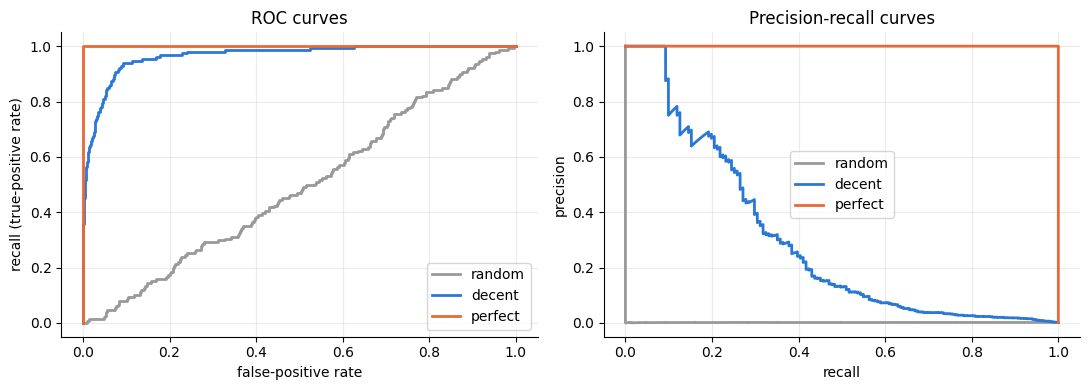

fraud rate of the demo data: 0.0015


,AUROC,AUPRC
model,,
random,0.494,0.001
decent,0.967,0.294
perfect,1.000,1.000


In [25]:
rng_demo = np.random.default_rng(0)
y_demo = (rng_demo.random(100_000) < 0.0017).astype(int)
logits = 4 * y_demo - 3 + 1.5 * rng_demo.normal(size=len(y_demo))
demo_scores = {
    "random": rng_demo.random(len(y_demo)),
    "decent": 1 / (1 + np.exp(-logits)),
    "perfect": 0.5 * y_demo + 0.5 * rng_demo.random(len(y_demo)),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rows = []
for (name, s), color in zip(demo_scores.items(), ["0.6", LEGIT_COLOR, FRAUD_COLOR]):
    fpr, tpr, _ = roc_curve(y_demo, s)
    precision, recall, _ = precision_recall_curve(y_demo, s)
    axes[0].plot(fpr, tpr, color=color, linewidth=2, label=name)
    axes[1].plot(recall, precision, color=color, linewidth=2, label=name)
    rows.append({"model": name, "AUROC": roc_auc_score(y_demo, s), "AUPRC": average_precision_score(y_demo, s)})
axes[0].set(xlabel="false-positive rate", ylabel="recall (true-positive rate)", title="ROC curves")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision-recall curves")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
print(f"fraud rate of the demo data: {y_demo.mean():.4f}")
pd.DataFrame(rows).set_index("model").round(3)

The "decent" model has an AUROC of about 0.97, which sounds excellent, yet its AUPRC is several times lower: at most recall levels, most of what it flags is a false alarm. The random model has AUROC ≈ 0.5 and AUPRC ≈ the fraud rate.

### 3.3 Only the order matters
AUROC and AUPRC depend only on the **ranking** of the scores. Any transformation that keeps the order (squaring positive scores, adding a constant, shrinking them towards 0.5) leaves them unchanged, whereas threshold-based metrics such as precision, recall and F1 at a fixed $t$ do change. Keep this in mind: in Part 10, noise does exactly this kind of shrinking to the scores of the quantum model.

✏️ **Exercise 3.2.** Shrink the "decent" scores towards 0.5 with $s \mapsto 0.5 + 0.2\,(s - 0.5)$, then compare AUPRC and the recall at the threshold $t = 0.8$ before and after.

In [27]:
scores = demo_scores["decent"]
squashed = 0.5 + 0.2 * (scores - 0.5)  # 0.5 + 0.2 * (scores - 0.5), computed on the whole array at once
for name, s in [("original", scores), ("squashed", squashed)]:
    tp, fp, fn, tn = confusion_counts(y_demo, (s >= 0.8).astype(int))
    print(f"{name:9s} AUPRC {average_precision_score(y_demo, s):.4f}   recall at t = 0.8: {tp / (tp + fn):.3f}   flagged: {tp + fp}")

original  AUPRC 0.2935   recall at t = 0.8: 0.384   flagged: 227
squashed  AUPRC 0.2935   recall at t = 0.8: 0.000   flagged: 0


In [28]:
# ✅ Check 3.2
assert squashed.shape == scores.shape and squashed.max() <= 0.6, "every squashed score should lie in [0.4, 0.6]"
assert np.isclose(average_precision_score(y_demo, squashed), average_precision_score(y_demo, scores))
passed("3.2")

✅ Exercise 3.2: all checks passed.


Same ranking, same AUPRC, but at the old threshold the squashed model flags nothing at all. The cure is not a better model but a new threshold, chosen on the new scores. Remember this in Part 10.

📝 **Quiz checkpoint B**: questions 6 to 11.

## Part 4 · Split, balance, encode

### 4.1 Optional: work on a smaller copy
A **stratified** sample keeps the fraud rate unchanged while making every later step faster. Try `SAMPLE_FRACTION = 0.3` (in Part 0) while experimenting; keep `1.0` for results you report, and for Task 2, where everybody uses the same split.

In [29]:
if SAMPLE_FRACTION < 1.0:
    df, _ = train_test_split(df, train_size=SAMPLE_FRACTION, stratify=df["Class"], random_state=SEED)
print(f"rows: {len(df):,}   frauds: {df['Class'].sum()}   fraud rate: {df['Class'].mean():.3%}")

rows: 284,807   frauds: 492   fraud rate: 0.173%


### 4.2 Split into train, validation and test
We split 60% / 20% / 20%. Two rules matter:
1. **Stratify**: every part keeps the fraud rate of the full data. With only 492 frauds, a purely random split could easily put 80 frauds in one test set and 115 in another.
2. **Split first, then do anything else.** Validation and test must look like the real world, where the model meets 0.17% fraud; balancing (next step) is applied to the training set only. Any step that lets information from validation or test reach training (fitting a scaler on the whole dataset, balancing before splitting, choosing a threshold on test) is called **data leakage**. It makes the reported results optimistic, and wrong.

`train_test_split(X, y, test_size=..., stratify=y, random_state=SEED)` from scikit-learn returns the two parts of `X` and then the two parts of `y`. We call it twice: first to cut off the test set, then to split what remains. In the second call, 20% of the original data is a quarter of the remaining 80%.

✏️ **Exercise 4.1.**

In [31]:
X = df.drop(columns="Class")
y = df["Class"].to_numpy()

# 1. cut off 20% of (X, y) as the test set; 2. split the remaining 80% into 60% train and 20% validation.
# stratify= takes the labels of the data being split.
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=42)  
pd.DataFrame(
    {
        "rows": [len(y_train), len(y_val), len(y_test)],
        "frauds": [y_train.sum(), y_val.sum(), y_test.sum()],
        "fraud rate": [f"{y_train.mean():.3%}", f"{y_val.mean():.3%}", f"{y_test.mean():.3%}"],
    },
    index=["train", "validation", "test"],
)

,rows,frauds,fraud rate
train,170883,295,0.173%
validation,56962,99,0.174%
test,56962,98,0.172%


In [32]:
# ✅ Check 4.1
assert abs(len(y_test) / len(y) - 0.2) < 0.001 and abs(len(y_val) / len(y) - 0.2) < 0.001, "validation and test should each hold 20% of the data"
assert max(abs(part.mean() - y.mean()) for part in [y_train, y_val, y_test]) < 0.0002, "every part should keep the fraud rate: did you stratify?"
assert not set(X_train.index) & set(X_test.index) and not set(X_val.index) & set(X_test.index), "the parts must not overlap"
if SAMPLE_FRACTION == 1.0:
    assert (len(y_test), int(y_test.sum()), int(y_val.sum())) == (56962, 98, 99), "use random_state=SEED so that everybody gets the same split"
passed("4.1")

✅ Exercise 4.1: all checks passed.


### 4.3 Balance the training set
The training set holds 295 frauds and about 170,000 legitimate transactions. Trained on it as it is, a model mostly sees legitimate examples and can make the loss small by always answering "legitimate"; simulating 170,000 circuits per epoch would also be slow. **Random undersampling** keeps all 295 training frauds and draws 295 legitimate transactions at random, which gives a balanced training set of 590 rows.

Two consequences:
- The model now believes that half of all transactions are fraud, so its scores come out too high for the real world: they are no longer **calibrated**. That is why the decision threshold is chosen later on the realistic validation set instead of being fixed at 0.5.
- We throw away 99.8% of the legitimate examples. 🔁 *Task 2 hook:* other ratios, several undersampled sets, or keeping more data and weighting the loss (`torch.nn.BCELoss(weight=...)`) are alternatives.

✏️ **Exercise 4.2.** Complete `undersample`. `np.flatnonzero(y_part == 0)` gives the positions of the legitimate rows, and `rng.choice(a, size=k, replace=False)` draws `k` distinct elements of the array `a`.

In [34]:
def undersample(X_part, y_part, seed):
    rng = np.random.default_rng(seed)
    fraud = np.flatnonzero(y_part == 1)
    legit = rng.choice(np.flatnonzero(y_part == 0), size=fraud.size, replace=False)   # as many distinct legitimate positions as there are frauds
    keep = rng.permutation(np.concatenate([fraud, legit]))   # shuffle, so that frauds are not all first
    return X_part.iloc[keep], y_part[keep]


X_bal, y_bal = undersample(X_train, y_train, SEED)
print(f"balanced training set: {len(y_bal)} rows, {y_bal.sum()} frauds, {len(y_bal) - y_bal.sum()} legitimate")

balanced training set: 590 rows, 295 frauds, 295 legitimate


In [35]:
# ✅ Check 4.2
assert len(y_bal) == 2 * y_train.sum() and y_bal.sum() == y_train.sum(), "keep every training fraud and as many legitimate rows"
assert X_bal.index.is_unique, "draw without replacement: no row may appear twice"
assert set(X_bal.index) <= set(X_train.index), "balance the training set only"
passed("4.2")

✅ Exercise 4.2: all checks passed.


### 4.4 Encode: from 30 features to 4 rotation angles
A 4-qubit circuit takes 4 numbers, one per qubit, and uses them as **rotation angles**. Three classical steps get us there:

1. **Standardise** `Time` and `Amount` with `StandardScaler`: subtract the mean and divide by the standard deviation, so that they no longer dwarf the other features (`V1`–`V28` are already centred).
2. **PCA**, principal component analysis, finds the directions along which the data varies most and keeps the first 4. The 4 new features are combinations of all 30 original ones and keep as much of their variation as 4 numbers can. (`V1`–`V28` themselves came out of a PCA done by the bank.)
3. **Rescale to $[0, \pi]$** with `MinMaxScaler`: the smallest training value becomes 0 and the largest becomes π. Rotations are periodic, so the range matters: with $x \in [0,\pi]$ the rotation RZ(2x) of the feature map (Part 6) turns by at most one full circle, and a larger range would send distant transactions to the same rotation. Validation and test values outside the training range are clipped into $[0, \pi]$.

Every step is **fitted on the balanced training set only** (the means, the principal directions, the minimum and maximum all come from training data) and then **applied unchanged** to validation and test. In scikit-learn, `.fit(data)` learns these quantities, `.transform(data)` applies them, and `.fit_transform(data)` does both at once.

✏️ **Exercise 4.3.** Complete `fit` and `transform`.

In [ ]:
class AngleEncoder:
    raw_columns = ["Time", "Amount"]

    def __init__(self, n_components, seed):
        self.scaler = StandardScaler()
        self.pca = PCA(n_components=n_components, random_state=seed)
        self.angles = MinMaxScaler(feature_range=(0, np.pi))

    def _scaled(self, frame):
        out = frame.copy()
        out[self.raw_columns] = self.scaler.transform(frame[self.raw_columns])
        return out.to_numpy()

    def fit(self, frame):
    
        self.scaler.fit(frame[self.raw_columns])
        pca_output = self.pca.fit_transform(self._scaled(frame))
        self.angles.fit(pca_output)
        return self

    def transform(self, frame):
        # scale -> PCA -> angles, then np.clip(..., 0, np.pi)

        return self.angles.transform(self.pca.transform(self._scaled(frame)))

explained variance per component: [0.664 0.117 0.073 0.035]
explained variance, 4 components: 88.9%


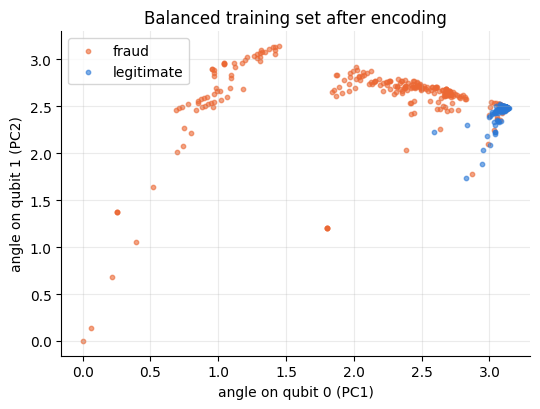

In [44]:
encoder = AngleEncoder(N_QUBITS, SEED).fit(X_bal)
Z_bal, Z_val, Z_test = encoder.transform(X_bal), encoder.transform(X_val), encoder.transform(X_test)
print("explained variance per component:", encoder.pca.explained_variance_ratio_.round(3))
print(f"explained variance, {N_QUBITS} components: {encoder.pca.explained_variance_ratio_.sum():.1%}")

fig, ax = plt.subplots(figsize=(5.5, 4.2))
for label, name, color in [(1, "fraud", FRAUD_COLOR), (0, "legitimate", LEGIT_COLOR)]:
    mask = y_bal == label
    ax.scatter(Z_bal[mask, 0], Z_bal[mask, 1], s=10, alpha=0.6, color=color, label=name)
ax.set_xlabel("angle on qubit 0 (PC1)")
ax.set_ylabel("angle on qubit 1 (PC2)")
ax.set_title("Balanced training set after encoding")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ✅ Check 4.3
assert Z_bal.shape == (len(y_bal), N_QUBITS), "one angle per qubit for every transaction"
assert np.allclose(Z_bal.min(axis=0), 0) and np.allclose(Z_bal.max(axis=0), np.pi), "training angles should span exactly [0, pi]"
assert encoder.pca.n_samples_ == len(X_bal), "fit the encoder on the balanced training set only"
passed("4.3")

✅ Exercise 4.3: all checks passed.


The first component carries most of the variance, and in the scatter plot the frauds spread over a much wider range of angles than the legitimate transactions, which crowd into a small region. 🔁 *Task 2 hook:* the number of components (that is, of qubits), the angle range and the choice of input features are all yours to change.

📝 **Quiz checkpoint C**: questions 12 to 16.

## Part 5 · PennyLane crash course

PennyLane describes a quantum computation with three ingredients:
1. a **device**, the machine that runs the circuit. `default.qubit` is an exact state-vector simulator; Part 10 uses `default.mixed`, which can simulate noise. Real hardware is reached through plugins in exactly the same way;
2. a **quantum function**, an ordinary Python function that applies gates (`qml.RY(theta, wires=0)`, `qml.CNOT(wires=[0, 1])`, …) and **returns a measurement**. Qubits are called *wires* and numbered from 0;
3. a **QNode**, which binds the function to the device. Calling the QNode runs the circuit and returns the measured value. The decorator `@qml.qnode(dev)` turns a function into a QNode.

| Measurement | Returns |
|---|---|
| `qml.expval(qml.PauliZ(0))` | the expectation value $\langle Z_0\rangle \in [-1, 1]$ |
| `qml.probs(wires=[0, 1])` | the probabilities of the outcomes 00, 01, 10, 11 |
| `qml.state()` | the full state vector (simulators only) |
| `qml.sample()` | individual measurement outcomes (needs shots, Section 5.3) |

PennyLane orders bits with wire 0 first: in `qml.probs(wires=[0, 1])`, entry 1 is the outcome `01`, wire 0 in $|0\rangle$ and wire 1 in $|1\rangle$.

### 5.1 One qubit
For $|\psi\rangle = RY(\theta)|0\rangle = \cos\frac{\theta}{2}|0\rangle + \sin\frac{\theta}{2}|1\rangle$, the expectation value is $\langle Z\rangle = \cos^2\frac{\theta}{2} - \sin^2\frac{\theta}{2} = \cos\theta$.

✏️ **Exercise 5.1.** Write the QNode.

In [47]:
dev1 = qml.device("default.qubit", wires=1, seed=SEED)   # the seed only matters once we use shots


@qml.qnode(dev1)
def ry_circuit(theta):
    qml.RY(theta, wires=0)
    return qml.expval(qml.PauliZ(wires=0))

In [48]:
# ✅ Check 5.1
for theta in [0.0, 0.5, np.pi / 2, 2.0, np.pi]:
    assert np.isclose(ry_circuit(theta), np.cos(theta)), f"<Z> after RY({theta:.2f}) should be cos(theta) = {np.cos(theta):.4f}"
passed("5.1")
print(qml.draw(ry_circuit)(0.5))

✅ Exercise 5.1: all checks passed.
0: ──RY(0.50)─┤  <Z>


### 5.2 Two qubits and entanglement
✏️ **Exercise 5.2.** Prepare the Bell state $(|00\rangle + |11\rangle)/\sqrt{2}$ with a Hadamard and a CNOT. Only the outcomes 00 and 11 should appear, each with probability 1/2.

In [49]:
dev2 = qml.device("default.qubit", wires=2)


@qml.qnode(dev2)
def bell():
    qml.Hadamard(wires=0)   
    qml.CNOT(wires=[0, 1])
    return qml.probs(wires=[0, 1])

In [50]:
# ✅ Check 5.2
assert np.allclose(bell(), [0.5, 0, 0, 0.5]), f"probabilities of 00, 01, 10, 11 should be [0.5, 0, 0, 0.5], got {np.round(bell(), 3)}"
passed("5.2")
print(qml.draw(bell)())

✅ Exercise 5.2: all checks passed.
0: ──H─╭●─┤ ╭Probs
1: ────╰X─┤ ╰Probs


### 5.3 Shots: what hardware really returns
A simulator returns exact expectation values; a quantum computer cannot. It runs the circuit, measures, gets one bit string, and starts again. Each repetition is a **shot**, and $\langle Z\rangle$ is estimated by the average of the ±1 outcomes. With $N$ shots, the estimate fluctuates around the true value with standard deviation

$$\sigma = \sqrt{\frac{1 - \langle Z\rangle^2}{N}},$$

so 4 times more shots only halve the error. In PennyLane, `qml.set_shots(qnode, shots=N)` returns a copy of a QNode that samples $N$ shots. Below, each estimate is repeated 200 times to measure its spread.

In [51]:
theta = 1.0
exact = ry_circuit(theta)
rows = []
for shots in [10, 100, 1000, 10000]:
    sampled = qml.set_shots(ry_circuit, shots=shots)
    estimates = np.array([sampled(theta) for _ in range(200)])
    rows.append({"shots": shots, "mean of 200 estimates": estimates.mean(), "spread of the estimates": estimates.std(), "theory: sqrt((1 - <Z>^2) / N)": np.sqrt((1 - exact**2) / shots)})
print(f"exact <Z> = cos(1) = {exact:.4f}")
pd.DataFrame(rows).set_index("shots").round(4)

exact <Z> = cos(1) = 0.5403


,mean of 200 estimates,spread of the estimates,theory: sqrt((1 - <Z>^2) / N)
shots,,,
10,0.5140,0.2853,0.2661
100,0.5384,0.0857,0.0841
1000,0.5404,0.0264,0.0266
10000,0.5402,0.0089,0.0084


### 5.4 Many inputs at once
Passing an array of angles to a QNode runs one circuit per entry and returns all the results (PennyLane calls this *parameter broadcasting*). With a 2-D array of shape `(n_transactions, 4)` this is how we will score 57,000 transactions in a single call. Inside a circuit, `x[..., i]` picks feature `i` whether `x` is one transaction or a whole batch of them.

In [52]:
thetas = np.linspace(0, np.pi, 5)
print("QNode:  ", np.round(ry_circuit(thetas), 4))
print("cos(θ): ", np.round(np.cos(thetas), 4))

QNode:   [ 1.      0.7071  0.     -0.7071 -1.    ]
cos(θ):  [ 1.      0.7071  0.     -0.7071 -1.    ]


### 5.5 Gradients of circuits
To train a circuit we need the derivative of its output with respect to its angles.

**On a simulator** the whole computation is ordinary linear algebra, and PyTorch can differentiate through it like any other function: `interface="torch"` with `diff_method="backprop"`. This is fast and exact.

**On a quantum computer** there is no state vector to differentiate. The **parameter-shift rule** gets the exact derivative from two more runs of the same circuit, with the angle shifted by ±π/2. For every gate of the form $e^{-i\theta P/2}$ with $P$ a Pauli operator (RX, RY, RZ, and the ZZ rotation of Part 6),

$$\frac{\partial f}{\partial \theta} = \frac{f(\theta + \pi/2) - f(\theta - \pi/2)}{2}.$$

This is not an approximation like the finite difference $[f(\theta+h)-f(\theta-h)]/2h$: it is exact, and because the two evaluations are far apart it is robust to shot noise (Schuld et al., 2019, [doi:10.1103/PhysRevA.99.032331](https://doi.org/10.1103/PhysRevA.99.032331)). The price is **two extra circuit executions per parameter, for every gradient**. With $P$ parameters, the gradient for one training example costs $1 + 2P$ executions: this number drives the cost ledger of Part 8.

In [53]:
@qml.qnode(dev1, interface="torch", diff_method="backprop")
def ry_torch(theta):
    qml.RY(theta, wires=0)
    return qml.expval(qml.PauliZ(0))


theta = torch.tensor(0.4, dtype=torch.float64, requires_grad=True)
value = ry_torch(theta)
value.backward()
print(f"<Z> = {value.item():.4f}   derivative by backprop = {theta.grad.item():.4f}   exact -sin(0.4) = {-np.sin(0.4):.4f}")

<Z> = 0.9211   derivative by backprop = -0.3894   exact -sin(0.4) = -0.3894


✏️ **Exercise 5.3: the parameter-shift rule.** Implement it for a function `f` of one angle. The check compares your result with backprop on a 2-qubit circuit.

In [56]:
def parameter_shift(f, theta):
    '''Derivative of f at theta from two shifted evaluations of f.'''
    return (f(theta + np.pi/2) - f(theta - np.pi/2)) / 2

In [57]:
# ✅ Check 5.3
@qml.qnode(dev2, interface="torch", diff_method="backprop")
def two_qubit_circuit(theta):
    qml.RX(0.3, wires=0)
    qml.RY(theta, wires=0)
    qml.CNOT(wires=[0, 1])
    qml.RX(0.7, wires=1)
    return qml.expval(qml.PauliZ(1))


for value in [0.1, 1.3, 2.5]:
    theta = torch.tensor(value, dtype=torch.float64, requires_grad=True)
    two_qubit_circuit(theta).backward()
    shift = parameter_shift(lambda t: two_qubit_circuit(torch.tensor(t, dtype=torch.float64)).item(), value)
    assert np.isclose(shift, theta.grad.item()), f"at theta = {value}: parameter shift gives {shift:.5f}, backprop {theta.grad.item():.5f}"
passed("5.3")

✅ Exercise 5.3: all checks passed.


Why does it matter that the rule is exact and uses big shifts? With shots, every evaluation is noisy. A finite difference divides the difference of two noisy numbers by a tiny $2h$, which blows the noise up; the parameter-shift rule divides by 2.

In [58]:
sampled = qml.set_shots(ry_circuit, shots=1000)
finite_difference = [(sampled(0.4 + 0.01) - sampled(0.4 - 0.01)) / 0.02 for _ in range(100)]
shift_rule = [parameter_shift(sampled, 0.4) for _ in range(100)]
print(f"exact derivative: {-np.sin(0.4):+.3f}")
print(f"finite difference (h = 0.01), 1000 shots: mean {np.mean(finite_difference):+.3f}, spread {np.std(finite_difference):.3f}")
print(f"parameter shift,              1000 shots: mean {np.mean(shift_rule):+.3f}, spread {np.std(shift_rule):.3f}")

exact derivative: -0.389
finite difference (h = 0.01), 1000 shots: mean -0.295, spread 0.849
parameter shift,              1000 shots: mean -0.388, spread 0.018


💡 **PennyLane shortcut.** You never have to code the rule yourself: a QNode created with `diff_method="parameter-shift"` applies it to every parameter (PennyLane also picks it automatically for QNodes with shots), and `qml.gradients.param_shift` exposes it as a transform.

📝 **Quiz checkpoint D**: questions 17 to 21.

## Part 6 · The variational quantum classifier

A VQC has three stages, and training goes around them in a loop:

```
transaction x ──► feature map U(x) ──► ansatz W(θ) ──► measure ⟨Z₀⟩ ──► p = (1 − ⟨Z₀⟩)/2 ──► loss
  (4 angles)       fixed, loads x       trainable                       fraud probability        │
                                            ▲                                                    │
                                            └──────────── classical optimiser (Adam) ◄───────────┘
```

1. The **feature map** (or encoding) $U(x)$ loads the data: a fixed circuit whose rotation angles are the features of the transaction. It has no trainable parameters.
2. The **ansatz** $W(\theta)$ is a circuit of trainable rotations and entangling gates, the quantum counterpart of the layers of a neural network.
3. The **readout** measures an observable and turns the result into a score.

The quantum computer only evaluates the circuit; the classical computer computes the loss and updates $\theta$. This **hybrid quantum-classical** loop is the common core of variational quantum algorithms (Cerezo et al., 2021, [doi:10.1038/s42254-021-00348-9](https://doi.org/10.1038/s42254-021-00348-9)).

### 6.1 The feature map: ZZ encoding
We use the ZZ feature map of Havlíček et al. (2019, [doi:10.1038/s41586-019-0980-2](https://doi.org/10.1038/s41586-019-0980-2)), Qiskit's `ZZFeatureMap`, as in the article. One repetition is
1. a Hadamard on every qubit, then $RZ(2x_i)$ on qubit $i$;
2. for every pair of qubits $i < j$ (*full* entanglement: 6 pairs for 4 qubits), a ZZ rotation $e^{-i\phi_{ij} Z_i Z_j/2}$ with $\phi_{ij} = 2(\pi - x_i)(\pi - x_j)$.

The ZZ rotation is built from gates you know: **CNOT(i → j), then RZ(φ) on j, then CNOT(i → j)**. The first CNOT writes the parity of the two qubits into qubit j, RZ applies a phase that depends on that parity, and the second CNOT undoes the parity. The products $(\pi - x_i)(\pi - x_j)$ mix the features in pairs, which a single-qubit encoding cannot do. We use 2 repetitions.

✏️ **Exercise 6.1.** Complete the ZZ block.

In [59]:
def feature_map(x):
    '''ZZ feature map. x holds N_QUBITS angles in [0, pi], or a batch of them (shape (..., N_QUBITS)).'''
    for _ in range(FEATURE_MAP_REPS):
        for i in range(N_QUBITS):
            qml.Hadamard(wires=i)
            qml.RZ(2 * x[..., i], wires=i)
        for i in range(N_QUBITS):
            for j in range(i + 1, N_QUBITS):
                # ZZ rotation between qubits i and j with angle phi = 2 (pi - x_i)(pi - x_j):
                # CNOT from i to j, RZ(phi) on j, CNOT from i to j. Write x_i as x[..., i].
                qml.CNOT(wires=[i, j])
                qml.RZ(2 * (np.pi - x[..., i]) * (np.pi - x[..., j]), wires=j)
                qml.CNOT(wires=[i, j])

In [60]:
# ✅ Check 6.1: compare with the same circuit written with PennyLane's IsingZZ gate
dev4 = qml.device("default.qubit", wires=N_QUBITS)


def state_of(circuit_fn, *args):
    '''Final state vector after running circuit_fn(*args) on |0000>.'''
    def full():
        circuit_fn(*args)
        return qml.state()
    return qml.QNode(full, dev4)()


def gate_counts(circuit_fn, *args):
    '''Number of native gates of each type in circuit_fn(*args).'''
    def full():
        circuit_fn(*args)
        return qml.state()
    return qml.specs(qml.transforms.decompose(qml.QNode(full, dev4), gate_set=NATIVE_GATES))()["resources"].gate_types


def feature_map_reference(x):
    for _ in range(FEATURE_MAP_REPS):
        for i in range(N_QUBITS):
            qml.Hadamard(wires=i)
            qml.RZ(2 * x[i], wires=i)
        for i in range(N_QUBITS):
            for j in range(i + 1, N_QUBITS):
                qml.IsingZZ(2 * (np.pi - x[i]) * (np.pi - x[j]), wires=[i, j])


for x_check in Z_bal[:3]:
    overlap = abs(np.vdot(state_of(feature_map_reference, x_check), state_of(feature_map, x_check))) ** 2
    assert np.isclose(overlap, 1.0), f"your feature map prepares a different state (overlap {overlap:.3f} instead of 1)"
passed("6.1")

✅ Exercise 6.1: all checks passed.


💡 **PennyLane shortcuts for encodings**
- `qml.IsingZZ(phi, wires=[i, j])` is exactly the CNOT–RZ–CNOT block (the check above used it; the next cell compares the matrices).
- `qml.IQPEmbedding(x, wires, n_repeats)` is a close cousin of the ZZ feature map with angles $x_i$ and $x_i x_j$ instead of $2x_i$ and $2(\pi-x_i)(\pi-x_j)$: same structure, different circuit. Conventions matter when you compare with a paper.
- `qml.AngleEmbedding(x, wires, rotation="Y")` is the simplest encoding: one rotation per feature and no entangling gates at all.
- `qml.AmplitudeEmbedding` stores $2^n$ features in the amplitudes of $n$ qubits: cheap in qubits, but preparing such a state on hardware takes a deep circuit.

🔁 *Task 2 hook:* the feature map is a large part of the circuit (see the gate counts below), so it is a natural place to save gates once noise enters.

In [61]:
def zz_block(phi):
    qml.CNOT(wires=[0, 1])
    qml.RZ(phi, wires=1)
    qml.CNOT(wires=[0, 1])


print("CNOT-RZ-CNOT equals IsingZZ:", np.allclose(qml.matrix(zz_block, wire_order=[0, 1])(0.7), qml.matrix(qml.IsingZZ(0.7, wires=[0, 1]))))

x_example = Z_bal[0]
iqp = lambda x: qml.IQPEmbedding(x, wires=range(N_QUBITS), n_repeats=FEATURE_MAP_REPS)
angle = lambda x: qml.AngleEmbedding(x, wires=range(N_QUBITS), rotation="Y")
print(f"overlap of the states prepared by our ZZ feature map and by IQPEmbedding: {abs(np.vdot(state_of(feature_map, x_example), state_of(iqp, x_example))) ** 2:.3f}")
for name, fm in [("ZZ feature map", feature_map), ("IQPEmbedding", iqp), ("AngleEmbedding", angle)]:
    print(f"{name:15s} native gates: {dict(gate_counts(fm, x_example))}")

CNOT-RZ-CNOT equals IsingZZ: True
overlap of the states prepared by our ZZ feature map and by IQPEmbedding: 0.004
ZZ feature map  native gates: {'Hadamard': 8, 'RZ': 20, 'CNOT': 24}
IQPEmbedding    native gates: {'Hadamard': 8, 'RZ': 20, 'CNOT': 24}
AngleEmbedding  native gates: {'RY': 4}


### 6.2 The ansatz: an EfficientSU2-style circuit
The trainable part follows Qiskit's `EfficientSU2`, as in the article: a layer of $RY$ and $RZ$ rotations on every qubit, then a **linear** ladder of CNOTs (0→1, 1→2, 2→3), repeated 3 times, and a final rotation layer. That makes (3 + 1) layers × 4 qubits × 2 angles = **32 trainable parameters**, stored in a tensor of shape `(4, 4, 2)`: `weights[layer, qubit, 0]` is an RY angle and `weights[layer, qubit, 1]` an RZ angle.

✏️ **Exercise 6.2.** Complete the ansatz.

In [71]:
def ansatz(weights):
    '''EfficientSU2-style ansatz; weights has shape (ANSATZ_REPS + 1, N_QUBITS, 2).'''
    for layer in range(ANSATZ_REPS + 1):
        for i in range(N_QUBITS):
            qml.RY(weights[layer, i, 0], wires=i)
            qml.RZ(weights[layer, i, 1], wires=i)
        if layer < ANSATZ_REPS:
            # linear entanglement: a CNOT from qubit i to qubit i + 1, for i = 0, ..., N_QUBITS - 2
            for i in range(N_QUBITS - 1):
                qml.CNOT(wires=[i, i + 1])

In [72]:
# ✅ Check 6.2
w_check = torch.linspace(0, 3, (ANSATZ_REPS + 1) * N_QUBITS * 2, dtype=torch.float64).reshape(ANSATZ_REPS + 1, N_QUBITS, 2)
counts = gate_counts(ansatz, w_check)
n_rotations, n_cnots = (ANSATZ_REPS + 1) * N_QUBITS, ANSATZ_REPS * (N_QUBITS - 1)
assert counts.get("RY", 0) == n_rotations and counts.get("RZ", 0) == n_rotations, f"expected {n_rotations} RY and {n_rotations} RZ gates, got {dict(counts)}"
assert counts.get("CNOT", 0) == n_cnots, f"expected {n_cnots} CNOTs, got {counts.get('CNOT', 0)}"
if (N_QUBITS, ANSATZ_REPS) == (4, 3):
    probabilities = np.abs(qml.math.to_numpy(state_of(ansatz, w_check))) ** 2
    assert np.allclose(probabilities[[0, 5, 10, 15]], [0.049016, 0.01134, 0.037841, 0.048166], atol=1e-5), "right gates, but not in the right order or with the right angles"
passed("6.2")

✅ Exercise 6.2: all checks passed.


💡 **PennyLane shortcuts for ansätze**: templates that build whole layers from a weight tensor.
- `qml.BasicEntanglerLayers(weights, wires)`: one rotation per qubit per layer and a ring of CNOTs; weights of shape `(layers, qubits)`.
- `qml.StronglyEntanglingLayers(weights, wires)`: a general rotation `qml.Rot` (3 angles) per qubit per layer, and CNOTs whose range changes from layer to layer; weights of shape `(layers, qubits, 3)`.
- `qml.SimplifiedTwoDesign`: RY rotations and CZ entanglers, a hardware-friendly choice.

Every template has a `shape` helper that gives the size of its weight tensor, and `qml.draw(..., level="device")` shows the gates inside a template:

In [73]:
print("BasicEntanglerLayers, 3 layers:", qml.BasicEntanglerLayers.shape(n_layers=3, n_wires=N_QUBITS))
print("StronglyEntanglingLayers, 2 layers:", qml.StronglyEntanglingLayers.shape(n_layers=2, n_wires=N_QUBITS))


@qml.qnode(dev4)
def strongly_entangling_demo(w):
    qml.StronglyEntanglingLayers(w, wires=range(N_QUBITS))
    return qml.expval(qml.PauliZ(0))


print(qml.draw(strongly_entangling_demo, level="device", decimals=None)(np.zeros(qml.StronglyEntanglingLayers.shape(n_layers=2, n_wires=N_QUBITS))))

BasicEntanglerLayers, 3 layers: (3, 4)
StronglyEntanglingLayers, 2 layers: (2, 4, 3)
0: ──Rot─╭●───────╭X──Rot─╭●────╭X────┤  <Z>
1: ──Rot─╰X─╭●────│───Rot─│──╭●─│──╭X─┤     
2: ──Rot────╰X─╭●─│───Rot─╰X─│──╰●─│──┤     
3: ──Rot───────╰X─╰●──Rot────╰X────╰●─┤     


### 6.3 Readout and the full circuit
Measuring qubit 0 gives the outcome 1 with probability $P(1) = \frac{1 - \langle Z_0\rangle}{2}$, a number in [0, 1] that we read as the **fraud probability**. Why qubit 0? Any qubit would do; it is the convention of the article. 🔁 *Task 2 hook:* the parity of several qubits, or a small classical rescaling of $\langle Z_0\rangle$, are other possible readouts.

The QNode uses `interface="torch"` (inputs and outputs are PyTorch tensors) and `diff_method="backprop"` (exact and fast gradients on the simulator). The initial weights are drawn uniformly in $[0, 2\pi)$ with a fixed seed.

✏️ **Exercise 6.3.** Assemble the circuit and the readout.

In [74]:
def vqc(x, weights):
             # encode the transaction(s) x
    feature_map(x)
    ansatz(weights)
    return qml.expval(qml.PauliZ(0))


device = qml.device("default.qubit", wires=N_QUBITS)
circuit = qml.QNode(vqc, device, interface="torch", diff_method="backprop")


def fraud_probability(x, weights):
    return (1 - circuit(x, weights)) / 2   # turn <Z_0> = circuit(x, weights), in [-1, 1], into P(qubit 0 = 1), in [0, 1]


def init_weights(seed):
    generator = torch.Generator().manual_seed(seed)
    return torch.nn.Parameter(2 * np.pi * torch.rand(ANSATZ_REPS + 1, N_QUBITS, 2, generator=generator, dtype=torch.float64))

In [75]:
# ✅ Check 6.3: compare with the probability that PennyLane reports for qubit 0
@qml.qnode(dev4, interface="torch")
def qubit0_probabilities(x, weights):
    feature_map(x)
    ansatz(weights)
    return qml.probs(wires=0)


example_x, example_w = torch.tensor(Z_bal[:5]), init_weights(SEED)
with torch.no_grad():
    p_yours = fraud_probability(example_x, example_w)
    p_reference = qubit0_probabilities(example_x, example_w)[:, 1]
assert p_yours.shape == (5,), "fraud_probability should return one number per transaction"
assert torch.allclose(p_yours, p_reference), "fraud_probability should be the probability of measuring 1 on qubit 0"
passed("6.3")

✅ Exercise 6.3: all checks passed.


Device: default.qubit
Device wires: 4
Shots: Shots(total=None)
Level: gradient

Wire allocations: 4
Total gates: 93
Gate counts:
- Hadamard: 8
- RZ: 36
- CNOT: 33
- RY: 16
Measurements:
- expval(PauliZ): 1
Depth: 45


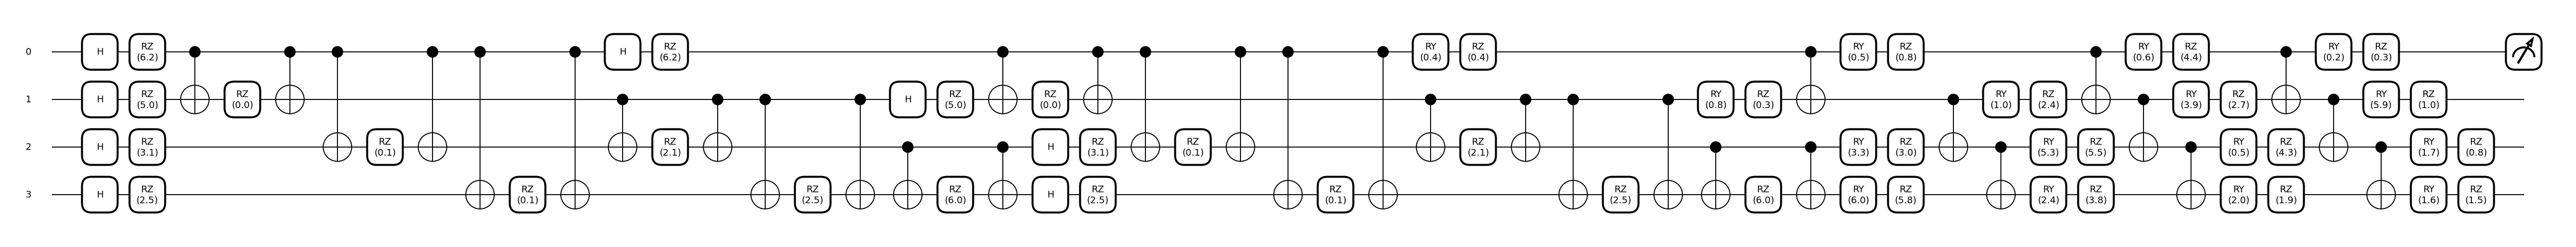

In [76]:
print(qml.specs(circuit)(example_x[0], example_w))
fig, ax = qml.draw_mpl(circuit, decimals=1)(example_x[0], example_w)
plt.show()

The circuit has 93 gates, 33 of them CNOTs, and a depth of 45: the longest chain of gates that have to run one after the other. On a simulator this hardly matters; on real hardware every gate adds a little error (Part 10).

💡 **PennyLane shortcut: `qml.qnn.TorchLayer`.** If you prefer the usual PyTorch style, a QNode can be wrapped into a `torch.nn.Module` that owns its weights and can be combined with classical layers in `torch.nn.Sequential`. The data argument of the circuit must then be called `inputs`:

In [77]:
def vqc_layer_circuit(inputs, weights):
    return vqc(inputs, weights)


qlayer = qml.qnn.TorchLayer(qml.QNode(vqc_layer_circuit, device, interface="torch"), weight_shapes={"weights": (ANSATZ_REPS + 1, N_QUBITS, 2)})
print("trainable parameters held by the layer:", sum(p.numel() for p in qlayer.parameters()))
print("<Z_0> for three transactions:", qlayer(torch.tensor(Z_bal[:3], dtype=torch.float32)).detach())

trainable parameters held by the layer: 32
<Z_0> for three transactions: tensor([0.4969, 0.5469, 0.4970])


**A word on initialisation.** For large circuits with random initial angles, gradients become exponentially small in the number of qubits, the **barren plateau** problem (McClean et al., 2018, [doi:10.1038/s41467-018-07090-4](https://doi.org/10.1038/s41467-018-07090-4)), and training stalls. At 4 qubits this is not an issue, but 🔁 *Task 2 hook:* starting close to the identity or with small angles (Grant et al., 2019, [doi:10.22331/q-2019-12-09-214](https://doi.org/10.22331/q-2019-12-09-214)) can help bigger or noisier circuits.

📝 **Quiz checkpoint E**: questions 22 to 25.

## Part 7 · Training

The training loop puts Parts 1 and 6 together. In every **epoch** it shuffles the 590 balanced training examples, cuts them into mini-batches of 32, and takes one Adam step on the binary cross-entropy of each batch. After every epoch it scores the **validation set** and remembers the weights of the epoch with the best validation AUPRC. Choosing the epoch on validation data is a form of *early stopping*: it protects against training for too long, and it is legitimate because the validation set is not the test set.

`predict` scores many transactions at once without recording gradients (`torch.no_grad()`), in chunks to limit memory. Both functions take an optional `model` (and `init`) argument, so that in Part 10 the same loop can train a noisy circuit, and in Task 2 your own one.

✏️ **Exercise 7.1.** Fill in the four-line training step of Part 1.

In [79]:
def predict(Z, weights, model=None, chunk=20000):
    model = model or fraud_probability
    X_t = torch.tensor(Z)
    with torch.no_grad():
        return torch.cat([model(X_t[k:k + chunk], weights) for k in range(0, len(X_t), chunk)]).numpy()


def train_vqc(Z_train, y_train_part, Z_valid, y_valid, seed, model=None, init=None, epochs=EPOCHS, verbose=True):
    model, init = model or fraud_probability, init or init_weights
    set_seed(seed)
    weights = init(seed)
    optimizer = torch.optim.Adam([weights], lr=LEARNING_RATE)
    loss_fn = torch.nn.BCELoss()
    X_t = torch.tensor(Z_train)
    y_t = torch.tensor(y_train_part, dtype=torch.float64)
    history, best_ap, best_weights = [], -1.0, None
    for epoch in range(1, epochs + 1):
        order = torch.randperm(len(X_t))
        losses = []
        for k in range(0, len(X_t), BATCH_SIZE):
            idx = order[k:k + BATCH_SIZE]
            optimizer.zero_grad()  # 1. reset the gradients
            loss = loss_fn(model(X_t[idx], weights), y_t[idx])  # 2. loss_fn between the fraud probabilities model(X_t[idx], weights) and the labels y_t[idx]
            loss.backward()  # 3. back-propagate
            optimizer.step()  # 4. update the weights
            losses.append(loss.item())
        val_ap = average_precision_score(y_valid, predict(Z_valid, weights, model))
        history.append({"epoch": epoch, "train loss": np.mean(losses), "validation AUPRC": val_ap})
        if val_ap > best_ap:
            best_ap, best_weights = val_ap, weights.detach().clone()
        if verbose:
            print(f"epoch {epoch:2d}   train loss {np.mean(losses):.4f}   validation AUPRC {val_ap:.3f}")
    return best_weights, pd.DataFrame(history)

epoch  1   train loss 0.4874   validation AUPRC 0.507
epoch  2   train loss 0.4287   validation AUPRC 0.497
epoch  3   train loss 0.4223   validation AUPRC 0.548
epoch  4   train loss 0.4000   validation AUPRC 0.545
epoch  5   train loss 0.3922   validation AUPRC 0.555
epoch  6   train loss 0.3870   validation AUPRC 0.600
epoch  7   train loss 0.3815   validation AUPRC 0.594
epoch  8   train loss 0.3735   validation AUPRC 0.581
epoch  9   train loss 0.3677   validation AUPRC 0.598
epoch 10   train loss 0.3763   validation AUPRC 0.600
epoch 11   train loss 0.3705   validation AUPRC 0.594
epoch 12   train loss 0.3720   validation AUPRC 0.554
epoch 13   train loss 0.3730   validation AUPRC 0.612
epoch 14   train loss 0.3701   validation AUPRC 0.594
epoch 15   train loss 0.3682   validation AUPRC 0.600
epoch 16   train loss 0.3680   validation AUPRC 0.604
epoch 17   train loss 0.3738   validation AUPRC 0.592
epoch 18   train loss 0.3680   validation AUPRC 0.591
epoch 19   train loss 0.3732

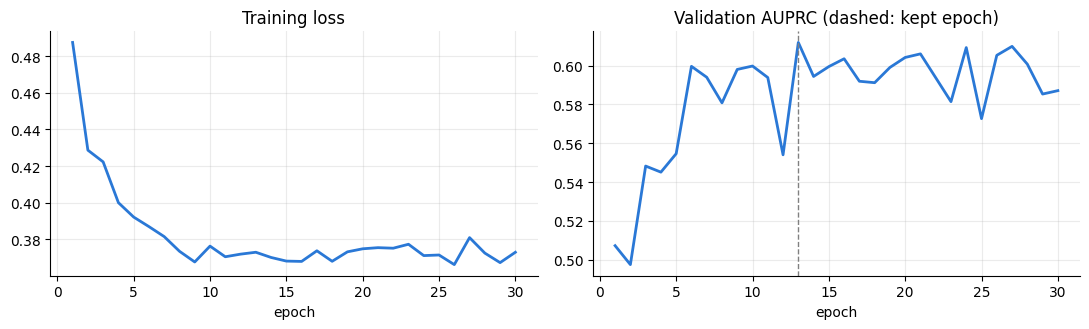

In [80]:
start = time.time()
weights, history = train_vqc(Z_bal, y_bal, Z_val, y_val, SEED)
best_epoch = int(history.loc[history["validation AUPRC"].idxmax(), "epoch"])
print(f"training time: {time.time() - start:.1f} s   best epoch: {best_epoch}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(history["epoch"], history["train loss"], color=LEGIT_COLOR, linewidth=2)
axes[0].set_title("Training loss")
axes[1].plot(history["epoch"], history["validation AUPRC"], color=LEGIT_COLOR, linewidth=2)
axes[1].axvline(best_epoch, color="0.5", linestyle="--", linewidth=1)
axes[1].set_title("Validation AUPRC (dashed: kept epoch)")
for ax in axes:
    ax.set_xlabel("epoch")
plt.tight_layout()
plt.show()

In [81]:
# ✅ Check 7.1
assert history["train loss"].iloc[-1] < history["train loss"].iloc[0], "the training loss should go down"
assert history["validation AUPRC"].max() > 0.3, "validation AUPRC should end far above the 0.0017 of random guessing"
passed("7.1")

✅ Exercise 7.1: all checks passed.


The training loss falls during the first epochs and then flattens out. Validation AUPRC climbs early and then moves up and down by a few points from epoch to epoch: the validation set has only 99 frauds, so moving a single fraud up or down the ranking changes AUPRC visibly. **Validation estimates are noisy**, and the best epoch is partly luck, one more reason to judge the final model on a separate test set.

## Part 8 · What training would cost on a quantum computer

On the simulator, training took seconds and the gradient came for free. On hardware:
- the gradient for each training example needs $1 + 2P$ circuit executions (parameter shift, Section 5.5), with $P = 32$;
- each execution is repeated for many **shots** (we assume 1,024) to estimate $\langle Z_0\rangle$;
- scoring the validation set after every epoch costs one execution per validation transaction.

The mini-batch size does not change the count: every example of a batch needs its own shifted circuits.

✏️ **Exercise 8.1.** Fill in the number of executions per training example; the ledger follows.

In [93]:
n_params = weights.numel()
executions_per_sample = 1 + 2 * n_params   # one plain run + two shifted runs per trainable parameter
ledger = pd.DataFrame(
    {
        "circuit executions": [
            EPOCHS * len(Z_bal) * executions_per_sample,
            EPOCHS * len(Z_val),
            len(Z_test),
        ]
    },
    index=["training (forward + parameter shift)", "validation after every epoch", "final test"],
)
ledger["shots"] = ledger["circuit executions"] * SHOTS_PER_EXECUTION
print(f"trainable parameters: {n_params}   executions per training example per epoch: {executions_per_sample}")
ledger.map(lambda v: f"{v:,}")

trainable parameters: 32   executions per training example per epoch: 65


,circuit executions,shots
training (forward + parameter shift),"1,150,500","1,178,112,000"
validation after every epoch,"1,708,860","1,749,872,640"
final test,"56,962","58,329,088"


In [94]:
# ✅ Check 8.1
assert executions_per_sample == 65 or (N_QUBITS, ANSATZ_REPS) != (4, 3), "with 32 parameters: 1 + 2 * 32"
passed("8.1")

SHOTS_PER_SECOND = 10_000   # an illustrative, optimistic throughput for a cloud quantum computer
print(f"at {SHOTS_PER_SECOND:,} shots per second this is {ledger['shots'].sum() / SHOTS_PER_SECOND / 3600:,.0f} hours of quantum-computer time")

✅ Exercise 8.1: all checks passed.
at 10,000 shots per second this is 83 hours of quantum-computer time


Two lessons for Task 2:
- **Scoring the validation set after every epoch costs more than training itself**: 1.7 million executions against 1.15 million. Validating less often, or on a smaller stratified subset, is the simplest saving there is.
- The ledger counts every parameter, but not every parameter matters. The next cell sends one mini-batch through PennyLane's own parameter-shift machinery, on a device with shots, and counts the executions with `qml.Tracker`.

In [95]:
shot_device = qml.device("default.qubit", wires=N_QUBITS, seed=SEED)
hardware_like = qml.set_shots(qml.QNode(vqc, shot_device, interface="torch", diff_method="parameter-shift"), shots=SHOTS_PER_EXECUTION)
batch_x, batch_y = torch.tensor(Z_bal[:BATCH_SIZE]), torch.tensor(y_bal[:BATCH_SIZE], dtype=torch.float64)
w_probe = init_weights(SEED)
with qml.Tracker(shot_device) as tracker:
    loss = torch.nn.BCELoss()((1 - hardware_like(batch_x, w_probe)) / 2, batch_y)
    loss.backward()
per_example = tracker.totals["executions"] / BATCH_SIZE
print(f"executions for one mini-batch of {BATCH_SIZE}: {tracker.totals['executions']:,}, that is {per_example:.0f} per example (the ledger assumed {executions_per_sample})")
print(f"shots: {tracker.totals['shots']:,}")

executions for one mini-batch of 32: 1,312, that is 41 per example (the ledger assumed 65)
shots: 1,343,488


PennyLane needs only 41 executions per example, not 65. From the wiring of the circuit it can tell that **12 of the 32 parameters can never influence qubit 0** (for example the last rotations on qubits 1, 2 and 3, which come after the last gate connecting those qubits to qubit 0), so it does not shift them. One more parameter, the final RZ on qubit 0, is shifted for nothing: it commutes with the Z measurement, so its gradient is always zero. Only 19 parameters really matter. Free savings of this kind are exactly what Task 2 asks you to look for. 🔁 `qml.Tracker` is also the simplest way to count the executions of your own training in Task 2.

📝 **Quiz checkpoint F**: questions 26 to 29.

## Part 9 · Testing against a classical reference

### 9.1 Choose the threshold on validation
Undersampling made the scores too high for the real world (Part 4), so 0.5 is not a sensible threshold. We take the threshold that maximises F1 on the **validation** set, never on the test set: that would leak test information into the model and inflate the result.

`precision_recall_curve(y, scores)` returns, for each candidate threshold `thresholds[k]`, the precision `precision[k]` and the recall `recall[k]` obtained by flagging every score `>= thresholds[k]`. The `precision` and `recall` arrays have one extra final entry (precision 1, recall 0) that belongs to no threshold.

✏️ **Exercise 9.1.**

In [96]:
def choose_threshold(y_true, scores):
    '''The threshold that maximises F1 on (y_true, scores).'''
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * (precision * recall) / np.clip(precision + recall, 1e-12, None)  # F1 for every entry; np.clip(precision + recall, 1e-12, None) avoids dividing by 0
    return thresholds[np.argmax(f1[:-1])]  # the threshold where F1 is largest: np.argmax over f1[:-1] (drop the extra last entry)


def evaluate(y_true, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "AUPRC": average_precision_score(y_true, scores),
        "AUROC": roc_auc_score(y_true, scores),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "MCC": matthews_corrcoef(y_true, predicted),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
    }

In [97]:
# ✅ Check 9.1: compare with a brute-force search over every possible threshold
rng_check = np.random.default_rng(3)
y_c = rng_check.integers(0, 2, 300)
s_c = np.clip(0.3 * y_c + rng_check.random(300), 0, 1)
best_f1 = max(f1_score(y_c, (s_c >= t).astype(int)) for t in np.unique(s_c))
assert np.isclose(f1_score(y_c, (s_c >= choose_threshold(y_c, s_c)).astype(int)), best_f1), "the threshold should maximise F1"
passed("9.1")

✅ Exercise 9.1: all checks passed.


### 9.2 Test the VQC, and a classical model on the same inputs
`evaluate` computes the metrics of Part 3 at a given threshold. Next to the VQC we train a **logistic regression on exactly the same four angles**. The comparison answers the question that matters: does the quantum circuit get more out of these four numbers than the simplest classical model? Without such a reference a quantum result cannot be interpreted. Bowles, Ahmed and Schuld (2024, [arXiv:2403.07059](https://arxiv.org/abs/2403.07059)) benchmarked many quantum models against classical ones and found the classical ones hard to beat.

In [98]:
vqc_val_scores, vqc_test_scores = predict(Z_val, weights), predict(Z_test, weights)
vqc_threshold = choose_threshold(y_val, vqc_val_scores)

reference = LogisticRegression(max_iter=1000).fit(Z_bal, y_bal)
ref_val_scores, ref_test_scores = reference.predict_proba(Z_val)[:, 1], reference.predict_proba(Z_test)[:, 1]
ref_threshold = choose_threshold(y_val, ref_val_scores)

results = pd.DataFrame(
    [evaluate(y_test, vqc_test_scores, vqc_threshold), evaluate(y_test, ref_test_scores, ref_threshold)],
    index=["VQC", "logistic regression, same 4 angles"],
)
print(f"VQC threshold chosen on validation: {vqc_threshold:.3f}")
results.round(3)

VQC threshold chosen on validation: 0.611


,AUPRC,AUROC,precision,recall,F1,MCC,TP,FP,FN,TN
VQC,0.659,0.960,0.696,0.653,0.674,0.673,64,28,34,56836
"logistic regression, same 4 angles",0.705,0.978,0.755,0.816,0.784,0.785,80,26,18,56838


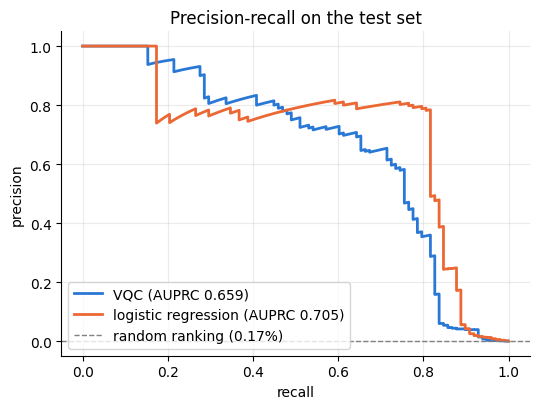

In [99]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
for name, scores, color in [("VQC", vqc_test_scores, LEGIT_COLOR), ("logistic regression", ref_test_scores, FRAUD_COLOR)]:
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ax.plot(recall, precision, color=color, linewidth=2, label=f"{name} (AUPRC {average_precision_score(y_test, scores):.3f})")
ax.axhline(y_test.mean(), color="0.5", linestyle="--", linewidth=1, label=f"random ranking ({y_test.mean():.2%})")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title("Precision-recall on the test set")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

The VQC ranks frauds far better than random (the dashed line), but the logistic regression on the same four angles does better still. The article found the same at four qubits: its VQC (AUPRC 0.494 ± 0.139 over 15 fits) stayed below tuned classical models (0.60 to 0.74).

### 9.3 Repeat over seeds
One training run is one random draw: another undersampling or another initialisation gives another result. Below, the split stays fixed while the undersampling, the encoder and the initial weights change with the seed. **Report the mean and the spread over seeds, never the best run.**

In [100]:
rows = []
start = time.time()
for seed in SEEDS:
    X_s, y_s = undersample(X_train, y_train, seed)
    enc = AngleEncoder(N_QUBITS, seed).fit(X_s)
    Zs_train, Zs_val, Zs_test = enc.transform(X_s), enc.transform(X_val), enc.transform(X_test)
    w_s, _ = train_vqc(Zs_train, y_s, Zs_val, y_val, seed, verbose=False)
    s_val, s_test = predict(Zs_val, w_s), predict(Zs_test, w_s)
    rows.append({"seed": seed, "model": "VQC", **evaluate(y_test, s_test, choose_threshold(y_val, s_val))})
    ref = LogisticRegression(max_iter=1000).fit(Zs_train, y_s)
    r_val, r_test = ref.predict_proba(Zs_val)[:, 1], ref.predict_proba(Zs_test)[:, 1]
    rows.append({"seed": seed, "model": "logistic regression", **evaluate(y_test, r_test, choose_threshold(y_val, r_val))})
    print(f"seed {seed}: VQC AUPRC {rows[-2]['AUPRC']:.3f}   logistic regression AUPRC {rows[-1]['AUPRC']:.3f}")
print(f"time: {time.time() - start:.0f} s")
seed_results = pd.DataFrame(rows)
seed_results.groupby("model")[["AUPRC", "AUROC", "F1", "MCC"]].agg(["mean", "std"]).round(3)

seed 0: VQC AUPRC 0.507   logistic regression AUPRC 0.700
seed 1: VQC AUPRC 0.551   logistic regression AUPRC 0.688
seed 2: VQC AUPRC 0.608   logistic regression AUPRC 0.710
seed 3: VQC AUPRC 0.596   logistic regression AUPRC 0.710
seed 4: VQC AUPRC 0.642   logistic regression AUPRC 0.711
time: 195 s


AUPRC         AUROC            F1           MCC       
                      mean    std   mean    std   mean    std   mean    std
model                                                                      
VQC                  0.581  0.052  0.968  0.003  0.650  0.032  0.651  0.032
logistic regression  0.704  0.010  0.976  0.003  0.792  0.020  0.792  0.019

The VQC varies several times more from seed to seed than the logistic regression: it is less stable. Stability across seeds is one of the judging criteria of Task 2.

📝 **Quiz checkpoint G**: questions 30 to 32.

## Part 10 · Noise

So far the qubits were perfect. Real qubits interact with their environment and real gates are imperfect, so a quantum computer does not prepare the state we asked for but a slightly random version of it.

### 10.1 Density matrices and the depolarizing channel
A state known only up to classical randomness ($|\psi_1\rangle$ with probability $q_1$, $|\psi_2\rangle$ with probability $q_2$, …) is a **mixed state**, described by a **density matrix** $\rho = \sum_k q_k |\psi_k\rangle\langle\psi_k|$. Expectation values become $\langle Z\rangle = \mathrm{Tr}(Z\rho)$. Noise maps density matrices to density matrices; such maps are called **quantum channels**.

The **depolarizing channel** with probability $p$ leaves the qubit alone with probability $1-p$ and applies X, Y or Z with probability $p/3$ each:

$$\mathcal{D}_p(\rho) = (1-p)\,\rho + \frac{p}{3}\left(X\rho X + Y\rho Y + Z\rho Z\right).$$

On the Bloch sphere it **shrinks the Bloch vector** towards the centre by the factor $1 - \tfrac{4p}{3}$, so every Pauli expectation value of that qubit is multiplied by the same factor. At $p = 3/4$ the qubit is completely random.

Density matrices cost more to simulate: $2^n \times 2^n$ numbers instead of $2^n$. PennyLane's `default.mixed` device does it; it accepts every gate of `default.qubit` plus noise channels such as `qml.DepolarizingChannel(p, wires=0)`.

✏️ **Exercise 10.1.** Apply RY(θ) and then a depolarizing channel, and check that $\langle Z\rangle = (1-\tfrac{4p}{3})\cos\theta$.

In [103]:
mixed1 = qml.device("default.mixed", wires=1)


@qml.qnode(mixed1)
def noisy_ry(theta, p):
    # the RY rotation by theta on wire 0
    qml.RY(theta, wires=0)
    # a depolarizing channel with probability p on wire 0
    qml.DepolarizingChannel(p, wires=0)
    return qml.expval(qml.PauliZ(0))

In [104]:
# ✅ Check 10.1
for theta, p in [(0.3, 0.0), (1.0, 0.1), (2.5, 0.3), (0.7, 0.75)]:
    assert np.isclose(noisy_ry(theta, p), (1 - 4 * p / 3) * np.cos(theta)), f"theta = {theta}, p = {p}: expected {(1 - 4 * p / 3) * np.cos(theta):.4f}"
passed("10.1")


@qml.qnode(mixed1)
def noisy_ry_state(theta, p):
    qml.RY(theta, wires=0)
    qml.DepolarizingChannel(p, wires=0)
    return qml.density_matrix(wires=0)


print("density matrix after RY(1.0), no noise:\n", np.round(noisy_ry_state(1.0, 0.0), 3))
print("density matrix after RY(1.0) and p = 0.3: the off-diagonal terms shrink, the diagonal moves towards 1/2\n", np.round(noisy_ry_state(1.0, 0.3), 3))

✅ Exercise 10.1: all checks passed.
density matrix after RY(1.0), no noise:
 [[0.77 +0.j 0.421+0.j]
 [0.421+0.j 0.23 +0.j]]
density matrix after RY(1.0) and p = 0.3: the off-diagonal terms shrink, the diagonal moves towards 1/2
 [[0.662+0.j 0.252+0.j]
 [0.252+0.j 0.338+0.j]]


### 10.2 Three ways to add noise to a circuit
1. **By hand**: place channels in the quantum function, as in the exercise.
2. **Everywhere at once**: `qml.noise.insert(qnode_or_device, qml.DepolarizingChannel, p, position="all")` inserts a channel after every gate, on every qubit that the gate acts on.
3. **With a noise model**: `qml.NoiseModel` maps conditions on gates to noise, for instance noise only after CNOTs, or stronger noise after two-qubit gates (usually the noisiest on real hardware), and `qml.add_noise` applies it.

In [105]:
mixed2 = qml.device("default.mixed", wires=2)


def bell_zz():
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0, 1])
    return qml.expval(qml.PauliZ(0) @ qml.PauliZ(1))


print("2. a depolarizing channel after every gate")
print(qml.draw(qml.noise.insert(qml.QNode(bell_zz, mixed2), qml.DepolarizingChannel, 0.01, position="all"))())


def depolarize_every_wire(op, **kwargs):
    for wire in op.wires:
        qml.DepolarizingChannel(0.05, wires=wire)


cnot_noise = qml.NoiseModel({qml.noise.op_eq("CNOT"): depolarize_every_wire})
print("\n3. a noise model: p = 0.05 after CNOTs only")
print(qml.draw(qml.add_noise(qml.QNode(bell_zz, mixed2), cnot_noise))())

2. a depolarizing channel after every gate
0: ──H──DepolarizingChannel(0.01)─╭●──DepolarizingChannel(0.01)─┤ ╭<Z@Z>
1: ───────────────────────────────╰X──DepolarizingChannel(0.01)─┤ ╰<Z@Z>

3. a noise model: p = 0.05 after CNOTs only
0: ──H─╭●──DepolarizingChannel(0.05)─┤ ╭<Z@Z>
1: ────╰X──DepolarizingChannel(0.05)─┤ ╰<Z@Z>


### 10.3 The noise model of this challenge
Task 2 compares everybody under the same simulated noise, implemented by `noisy_qnode` below and used for the rest of this notebook:
1. the circuit is first **decomposed** into the native gate set `NATIVE_GATES` = {RX, RY, RZ, Rot, H, CNOT, CZ}. Templates, `IsingZZ` gates or multi-qubit unitaries are charged for the elementary gates they are made of, so a deep circuit cannot hide inside a single "gate";
2. a **depolarizing channel of probability $p$ follows every gate, on every qubit the gate touches** (a CNOT gets two channels);
3. $p$ takes the values of `NOISE_LEVELS` = 0.001, 0.01 and 0.05. Two-qubit gate errors on today's best hardware are around $10^{-3}$ to $10^{-2}$; 0.05 is a stress test.

The noise is simulated exactly with density matrices, so the results do not fluctuate; shot noise is accounted for separately, in the cost ledger. `noise_locations` counts the channels a circuit collects.

In [106]:
def noisy_qnode(circuit_fn, p, n_wires=N_QUBITS):
    '''QNode of circuit_fn under the challenge's noise model: native gates, then a depolarizing channel of
    probability p after every gate, on each of its qubits. Differentiable with backprop.'''
    noisy_device = qml.noise.insert(qml.device("default.mixed", wires=n_wires), qml.DepolarizingChannel, p, position="all")
    qnode = qml.QNode(circuit_fn, noisy_device, interface="torch", diff_method="backprop")
    return qml.transforms.decompose(qnode, gate_set=NATIVE_GATES)


def noisy_predict(Z, weights, p, circuit_fn=vqc, readout=lambda expval: (1 - expval) / 2, n_wires=N_QUBITS, chunk=2000):
    '''Fraud scores of the transactions Z when circuit_fn runs under depolarizing noise p.'''
    noisy_circuit = noisy_qnode(circuit_fn, p, n_wires)
    X_t = torch.tensor(Z)
    with torch.no_grad():
        return torch.cat([readout(noisy_circuit(X_t[k:k + chunk], weights)) for k in range(0, len(X_t), chunk)]).numpy()


def noise_locations(circuit_fn, *args, n_wires=N_QUBITS):
    '''Number of depolarizing channels the noise model inserts: one per qubit of every native gate.'''
    qnode = qml.transforms.decompose(qml.QNode(circuit_fn, qml.device("default.qubit", wires=n_wires)), gate_set=NATIVE_GATES)
    return sum(size * count for size, count in qml.specs(qnode)(*args)["resources"].gate_sizes.items())


sanity = np.abs(noisy_predict(Z_test[:2000], weights, 0.0) - vqc_test_scores[:2000]).max()
print(f"density-matrix simulator at p = 0 vs state-vector simulator, max difference: {sanity:.1e}")
print(f"noise locations in the VQC: {noise_locations(vqc, example_x[0], weights)}")

density-matrix simulator at p = 0 vs state-vector simulator, max difference: 6.4e-08
noise locations in the VQC: 126


### 10.4 The trained VQC under noise
We now run the weights trained without noise (Part 7) on the noisy simulator, over the whole test set, and keep the threshold chosen on noiseless validation scores. Besides AUPRC we compute the **Spearman rank correlation ρ** between noisy and noiseless scores: ρ = 1 means that noise kept the order of the transactions exactly, ρ near 0 that it scrambled it. As the article points out, AUPRC alone can hide a decaying ranking. This takes about half a minute per noise level.

✏️ **Exercise 10.2.** Compute ρ with `spearmanr(a, b).statistic`.

In [108]:
noisy_test = {}
noise_rows = [{"p": 0.0, **evaluate(y_test, vqc_test_scores, vqc_threshold), "Spearman rho": 1.0}]
for p in NOISE_LEVELS:
    start = time.time()
    noisy_test[p] = noisy_predict(Z_test, weights, p)
    rho = spearmanr(vqc_test_scores, noisy_test[p]).correlation  # Spearman rank correlation between vqc_test_scores and noisy_test[p]
    noise_rows.append({"p": p, **evaluate(y_test, noisy_test[p], vqc_threshold), "Spearman rho": rho})
    print(f"p = {p}: {time.time() - start:.0f} s")
noise_results = pd.DataFrame(noise_rows).set_index("p")
noise_results[["AUPRC", "Spearman rho", "precision", "recall", "F1", "TP", "FP"]].round(3)

p = 0.001: 48 s
p = 0.01: 70 s
p = 0.05: 41 s


,AUPRC,Spearman rho,precision,recall,F1,TP,FP
p,,,,,,,
0.000,0.659,1.000,0.696,0.653,0.674,64,28
0.001,0.658,1.000,0.705,0.633,0.667,62,26
0.010,0.617,0.991,0.735,0.255,0.379,25,9
0.050,0.512,0.653,0.000,0.000,0.000,0,0


✅ Exercise 10.2: all checks passed.


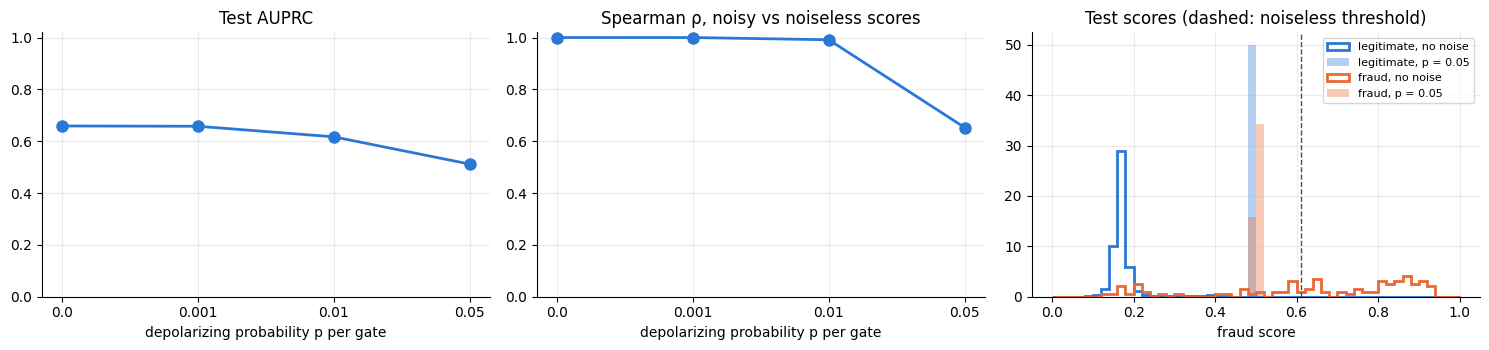

In [109]:
# ✅ Check 10.2
p_max = NOISE_LEVELS[-1]
assert np.isclose(noise_results.loc[p_max, "Spearman rho"], pd.Series(vqc_test_scores).corr(pd.Series(noisy_test[p_max]), method="spearman"))
passed("10.2")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
levels = [str(p) for p in noise_results.index]
axes[0].plot(levels, noise_results["AUPRC"], marker="o", markersize=8, color=LEGIT_COLOR, linewidth=2)
axes[0].set_title("Test AUPRC")
axes[1].plot(levels, noise_results["Spearman rho"], marker="o", markersize=8, color=LEGIT_COLOR, linewidth=2)
axes[1].set_title("Spearman ρ, noisy vs noiseless scores")
for ax in axes[:2]:
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("depolarizing probability p per gate")
bins = np.linspace(0, 1, 51)
for label, name, color in [(0, "legitimate", LEGIT_COLOR), (1, "fraud", FRAUD_COLOR)]:
    axes[2].hist(vqc_test_scores[y_test == label], bins=bins, density=True, histtype="step", linewidth=2, color=color, label=f"{name}, no noise")
    axes[2].hist(noisy_test[p_max][y_test == label], bins=bins, density=True, alpha=0.35, color=color, label=f"{name}, p = {p_max}")
axes[2].axvline(vqc_threshold, color="0.3", linestyle="--", linewidth=1)
axes[2].set_title("Test scores (dashed: noiseless threshold)")
axes[2].set_xlabel("fraud score")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

At $p = 0.001$ almost nothing changes. At $p = 0.01$ AUPRC drops a little and ρ stays close to 1, but **recall falls sharply**: noise pulls every score towards 0.5 (right plot), many frauds drop below the threshold chosen without noise, and they are no longer flagged. At $p = 0.05$ the ranking itself is damaged (ρ well below 1) and the model flags nothing at all.

### 10.5 First fix: choose the threshold under the same noise
On a real device you would score the validation set on the same noisy hardware, so the threshold should be chosen on **noisy validation scores**. It costs one pass over the validation set and changes nothing in the circuit, and since AUPRC does not depend on the threshold, it cannot change AUPRC either. It only repairs the decisions. The Task 2 evaluation protocol always does this.

✏️ **Exercise 10.3.**

In [110]:
noisy_val = {}
recalibrated_rows = []
for p in NOISE_LEVELS:
    noisy_val[p] = noisy_predict(Z_val, weights, p)
    threshold_p = choose_threshold(y_val, noisy_val[p])  # the F1-optimal threshold on the NOISY validation scores noisy_val[p]
    recalibrated_rows.append({"p": p, "threshold": threshold_p, **evaluate(y_test, noisy_test[p], threshold_p)})
recalibrated = pd.DataFrame(recalibrated_rows).set_index("p")
pd.DataFrame(
    {
        "recall, noiseless threshold": noise_results.loc[NOISE_LEVELS, "recall"],
        "recall, noisy threshold": recalibrated["recall"],
        "F1, noiseless threshold": noise_results.loc[NOISE_LEVELS, "F1"],
        "F1, noisy threshold": recalibrated["F1"],
        "noisy threshold": recalibrated["threshold"],
    }
).round(3)

,"recall, noiseless threshold","recall, noisy threshold","F1, noiseless threshold","F1, noisy threshold",noisy threshold
p,,,,,
0.001,0.633,0.643,0.667,0.667,0.600
0.010,0.255,0.673,0.379,0.698,0.541
0.050,0.000,0.765,0.000,0.620,0.499


In [111]:
# ✅ Check 10.3
assert recalibrated.loc[p_max, "recall"] > 0, "with a threshold chosen on noisy validation scores, some frauds should be caught again"
assert abs(recalibrated.loc[p_max, "threshold"] - 0.5) < abs(vqc_threshold - 0.5), "the noisy threshold should sit closer to 0.5"
passed("10.3")

✅ Exercise 10.3: all checks passed.


### 10.6 Why gate noise scrambles the ranking
If the only noise were a single depolarizing channel on qubit 0 just before the measurement, every $\langle Z_0\rangle$ would be multiplied by the same factor $1-\tfrac{4p}{3}$, every score would move towards 0.5 in the same proportion, and **the ranking would not change** (Section 3.3). Gate noise is different: the channels sit in the middle of the circuit, the gates that follow spread their effect around, and different transactions are damaged differently. The next cell compares both situations on the first 10,000 test transactions.

In [112]:
def vqc_with_final_noise(x, weights, p=0.3):
    feature_map(x)
    ansatz(weights)
    qml.DepolarizingChannel(p, wires=0)
    return qml.expval(qml.PauliZ(0))


final_noise = qml.QNode(vqc_with_final_noise, qml.device("default.mixed", wires=N_QUBITS), interface="torch")
subset = slice(0, 10_000)
with torch.no_grad():
    final_noise_scores = ((1 - final_noise(torch.tensor(Z_test[subset]), weights)) / 2).numpy()
print(f"one channel (p = 0.3) on qubit 0, just before the measurement: Spearman rho = {spearmanr(vqc_test_scores[subset], final_noise_scores).statistic:.4f}")
print(f"a channel (p = {p_max}) after every gate:                       Spearman rho = {spearmanr(vqc_test_scores[subset], noisy_test[p_max][subset]).statistic:.4f}")

one channel (p = 0.3) on qubit 0, just before the measurement: Spearman rho = 1.0000
a channel (p = 0.05) after every gate:                       Spearman rho = 0.6606


The more gates a circuit has, the more channels it collects: 126 for our VQC. Crudely, if each channel leaves the state intact with probability $1 - p$, the chance that the whole circuit runs without a single error is about $(1-p)^{126}$: 88% at $p = 0.001$, 28% at $p = 0.01$ and 0.2% at $p = 0.05$. Only the channels inside the *light cone* of qubit 0 actually matter, so the real damage is smaller, but the message is clear: **under noise, fewer gates, and above all fewer two-qubit gates, is better**, even if the circuit becomes less expressive. Noise also makes gradients vanish exponentially with depth, the *noise-induced barren plateaus* of Wang et al. (2021, [doi:10.1038/s41467-021-27045-6](https://doi.org/10.1038/s41467-021-27045-6)).

### 10.7 Tools for Task 2
Four tools you are likely to need, each on a small example.

**(a) Noise-aware training.** The noisy QNode is differentiable (`diff_method="backprop"` through the density matrix), so the training loop of Part 7 can train **inside** the noise model, and the optimiser can then adapt to what noise does to the circuit (see for example QuantumNAT, Wang et al., 2022, [doi:10.1145/3489517.3530400](https://doi.org/10.1145/3489517.3530400)). Each epoch is several times slower than without noise, and scoring the whole validation set under noise after every epoch would dominate the time, so this demo validates on a stratified 20% subset of the validation set and runs only 10 epochs (about 2 minutes).

In [113]:
P_TRAIN = p_max
noisy_circuit_train = noisy_qnode(vqc, P_TRAIN)


def noisy_fraud_probability(x, weights):
    return (1 - noisy_circuit_train(x, weights)) / 2


Z_val_small, _, y_val_small, _ = train_test_split(Z_val, y_val, train_size=0.2, stratify=y_val, random_state=SEED)
start = time.time()
weights_noise_aware, history_noise_aware = train_vqc(Z_bal, y_bal, Z_val_small, y_val_small, SEED, model=noisy_fraud_probability, epochs=10, verbose=False)
print(f"noise-aware training, 10 epochs at p = {P_TRAIN}: {time.time() - start:.0f} s")

noise_aware_test = noisy_predict(Z_test, weights_noise_aware, P_TRAIN)
print(f"test AUPRC at p = {P_TRAIN}:  trained without noise {average_precision_score(y_test, noisy_test[P_TRAIN]):.3f}   trained under noise {average_precision_score(y_test, noise_aware_test):.3f}")

noise-aware training, 10 epochs at p = 0.05: 189 s
test AUPRC at p = 0.05:  trained without noise 0.512   trained under noise 0.453


One seed and 10 epochs prove nothing either way. Whether, when and how noise-aware training helps is exactly the kind of question Task 2 is about.

**(b) Counting what you spend.** `qml.Tracker` (Part 8) counts the executions and shots of any device.

**(c) Cheaper gradients: SPSA.** The parameter-shift gradient costs $2P$ executions. **SPSA** (Spall, 1992, [doi:10.1109/9.119632](https://doi.org/10.1109/9.119632)) estimates the whole gradient from **2 executions**, whatever $P$: shift all parameters at once along a random direction $\Delta$ whose entries are ±1, and use $\hat g = \frac{L(\theta + c\Delta) - L(\theta - c\Delta)}{2c}\,\Delta$. A single estimate is very noisy but points downhill on average. PennyLane also provides it as `qml.SPSAOptimizer`.

In [114]:
def spsa_gradient(loss_of, weights, c=0.1, generator=None):
    delta = 2 * torch.randint(0, 2, weights.shape, generator=generator).to(weights.dtype) - 1   # random +1 / -1 entries
    with torch.no_grad():
        difference = loss_of(weights + c * delta) - loss_of(weights - c * delta)
    return difference / (2 * c) * delta


loss_fn = torch.nn.BCELoss()
loss_of = lambda w: loss_fn(fraud_probability(batch_x, w), batch_y)
w_probe = init_weights(SEED)
loss_of(w_probe).backward()
exact_gradient = w_probe.grad.flatten()

generator = torch.Generator().manual_seed(SEED)
estimates = torch.stack([spsa_gradient(loss_of, w_probe.detach(), generator=generator).flatten() for _ in range(200)])
cosine = lambda a, b: (a @ b / (a.norm() * b.norm())).item()
print(f"cosine similarity with the exact gradient: one SPSA estimate {cosine(estimates[0], exact_gradient):.2f}, mean of 200 estimates {cosine(estimates.mean(0), exact_gradient):.2f}")
print(f"executions per example and gradient: parameter shift {1 + 2 * w_probe.numel()}, SPSA 2")

cosine similarity with the exact gradient: one SPSA estimate -0.00, mean of 200 estimates 0.92
executions per example and gradient: parameter shift 65, SPSA 2


**(d) Error mitigation: zero-noise extrapolation (ZNE).** Run the circuit at the real noise level and at artificially amplified levels, then extrapolate the results back to zero noise (Temme, Bravyi and Gambetta, 2017, [doi:10.1103/PhysRevLett.119.180509](https://doi.org/10.1103/PhysRevLett.119.180509)). The noise is amplified by *folding*: the circuit $U$ is replaced by $U U^\dagger U$, which computes the same thing with three times as many gates, hence about three times the noise. ZNE changes neither the circuit nor the training, but it multiplies the number of executions (here by 3, for the scale factors 1, 3 and 5) and runs longer circuits.

In [115]:
P_ZNE = 0.01
zne_circuit = qml.noise.mitigate_with_zne(
    noisy_qnode(vqc, P_ZNE), scale_factors=[1, 3, 5], folding=qml.noise.fold_global, extrapolate=qml.noise.richardson_extrapolate
)
sample = slice(0, 500)
with torch.no_grad():
    zne_expvals = zne_circuit(torch.tensor(Z_test[sample]), weights)
zne_expvals = torch.stack(list(zne_expvals)) if isinstance(zne_expvals, (tuple, list)) else zne_expvals
zne_scores = ((1 - zne_expvals) / 2).numpy()
noisy_sample = noisy_predict(Z_test[sample], weights, P_ZNE)
print(f"mean |score - noiseless score| over 500 test transactions at p = {P_ZNE}:")
print(f"  noisy:          {np.abs(noisy_sample - vqc_test_scores[sample]).mean():.4f}")
print(f"  ZNE-mitigated:  {np.abs(zne_scores - vqc_test_scores[sample]).mean():.4f}")

mean |score - noiseless score| over 500 test transactions at p = 0.01:
  noisy:          0.1715
  ZNE-mitigated:  0.0802


🔁 Other directions, such as shot-frugal optimisers, layerwise training, data re-uploading or classical surrogates, are listed with their references in the task description.

📝 **Quiz checkpoint H**: questions 33 to 40.

## Part 11 · Working with the dataset in Task 2, and the challenge

### 11.1 The common split
Task 2 starts again from the original dataset, and every participant uses **the same split**: the one made in Part 4 with `SEED = 42` and `SAMPLE_FRACTION = 1.0`. The next cell saves the row numbers of the three parts in `split_indices.npz`; the comment shows how to load them at the start of your Task 2 code. Inside the training rows you may do anything (other balancing, other encodings, other seeds); validation is for every decision you take; test is only for reporting final results.

In [116]:
if SAMPLE_FRACTION == 1.0:
    np.savez("split_indices.npz", train=X_train.index.to_numpy(), val=X_val.index.to_numpy(), test=X_test.index.to_numpy())
    split = np.load("split_indices.npz")
    assert (df["Class"].to_numpy()[split["test"]] == y_test).all()
    print("saved split_indices.npz:", {name: len(split[name]) for name in ["train", "val", "test"]})
else:
    print("set SAMPLE_FRACTION = 1.0 and rerun the notebook to save the common split")

# In your Task 2 code, with df loaded as in Part 2:
# split = np.load("split_indices.npz")
# X_all, y_all = df.drop(columns="Class"), df["Class"].to_numpy()
# X_train, y_train = X_all.loc[split["train"]], y_all[split["train"]]
# X_val, y_val = X_all.loc[split["val"]], y_all[split["val"]]
# X_test, y_test = X_all.loc[split["test"]], y_all[split["test"]]

saved split_indices.npz: {'train': 170883, 'val': 56962, 'test': 56962}


### 11.2 The evaluation protocol
`evaluate_under_noise` packages Part 10 into the evaluation protocol of Task 2. For a circuit and its trained weights it scores validation and test without noise and at every level of `NOISE_LEVELS`, chooses the threshold on validation scores **at the same noise level**, and reports test AUPRC (the primary metric), AUROC, the Spearman ρ between noisy and noiseless test scores, and the metrics at the threshold. Run it once per seed and report the mean and the spread. For the baseline it takes about 3 to 4 minutes (two noisy passes over 57,000 transactions per noise level).

🔁 To evaluate your own model, pass your circuit function (`circuit_fn(x, weights)` returning an expectation value), its weights, your encoded validation and test sets, your readout if it is not $(1 - \langle Z_0\rangle)/2$, and `n_wires` if you do not use 4 qubits.

In [117]:
def evaluate_under_noise(circuit_fn, weights, Z_valid, Z_test_part, y_valid=y_val, y_test_part=y_test,
                         readout=lambda expval: (1 - expval) / 2, noise_levels=NOISE_LEVELS, n_wires=N_QUBITS):
    clean = qml.QNode(circuit_fn, qml.device("default.qubit", wires=n_wires), interface="torch")
    with torch.no_grad():
        clean_val = readout(clean(torch.tensor(Z_valid), weights)).numpy()
        clean_test = readout(clean(torch.tensor(Z_test_part), weights)).numpy()
    rows = []
    for p in [0.0, *noise_levels]:
        if p == 0.0:
            val_scores, test_scores = clean_val, clean_test
        else:
            val_scores = noisy_predict(Z_valid, weights, p, circuit_fn, readout, n_wires)
            test_scores = noisy_predict(Z_test_part, weights, p, circuit_fn, readout, n_wires)
        threshold = choose_threshold(y_valid, val_scores)
        rows.append({"p": p, **evaluate(y_test_part, test_scores, threshold), "Spearman rho": spearmanr(clean_test, test_scores).statistic, "threshold": threshold})
    return pd.DataFrame(rows).set_index("p")


start = time.time()
baseline_protocol = evaluate_under_noise(vqc, weights, Z_val, Z_test)
print(f"time: {time.time() - start:.0f} s")
baseline_protocol[["AUPRC", "AUROC", "Spearman rho", "precision", "recall", "F1", "MCC", "threshold"]].round(3)

time: 318 s


,AUPRC,AUROC,Spearman rho,precision,recall,F1,MCC,threshold
p,,,,,,,,
0.000,0.659,0.960,1.000,0.696,0.653,0.674,0.673,0.611
0.001,0.658,0.960,1.000,0.692,0.643,0.667,0.667,0.600
0.010,0.617,0.960,0.991,0.725,0.673,0.698,0.698,0.541
0.050,0.512,0.964,0.653,0.521,0.765,0.620,0.631,0.499


This table, repeated over 5 seeds, is the **baseline of Task 2**: your improvements are measured against it.

Read it closely. With the threshold chosen under noise, F1 at $p = 0.01$ (0.698) comes out *higher* than without noise (0.677), and at $p = 0.05$ AUROC (0.964) is higher than without noise (0.960), while Spearman ρ shows that the ranking of the transactions decayed. On a single seed, one metric can report an improvement where the model got worse: this is the trap the article warns about. Read several metrics together, and over several seeds.

A template to start from:

In [118]:
# A Task 2 template: change the circuit, keep the protocol.
#
# def my_circuit(x, weights):
#     ...                                            # your encoding and ansatz
#     return qml.expval(qml.PauliZ(0))
#
# my_qnode = qml.QNode(my_circuit, device, interface="torch", diff_method="backprop")   # or noisy_qnode(my_circuit, p)
# my_model = lambda x, w: (1 - my_qnode(x, w)) / 2
# my_init = lambda seed: torch.nn.Parameter(...)    # initial weights of the right shape
# my_weights, my_history = train_vqc(Z_bal, y_bal, Z_val, y_val, seed, model=my_model, init=my_init)
# print("noise locations:", noise_locations(my_circuit, torch.tensor(Z_bal[0]), my_weights))
# evaluate_under_noise(my_circuit, my_weights, Z_val, Z_test)
def my_circuit(x, weights):
    feature_map(x)
    ansatz(weights)
    qml.DepolarizingChannel(0.3, wires=0)
    return qml.expval(qml.PauliZ(0))
    

### 11.3 The challenge
**Task 2: the best fraud detector under noise, on a quantum budget.** Build your own end-to-end VQC pipeline, reusing anything from this notebook, make its fraud detection hold up as well as possible under the noise model of Part 10, and keep track of what its training would cost on a real quantum computer.

Every submission contains:
1. **the baseline**: the VQC of this notebook, evaluated with `evaluate_under_noise` over 5 seeds;
2. **at least one improvement aimed at noise**, evaluated in the same way over at least 5 seeds and compared with the baseline. Choosing the threshold on noisy validation does not count: it is already part of the protocol;
3. **a classical reference**, at least the logistic regression, trained on the same inputs as your circuit;
4. **a cost ledger** for the baseline and for your method: circuit executions and shots for training and validation, counted with the formula of Part 8 or with `qml.Tracker`.

The headline numbers are the test AUPRC at $p = 0.01$ and $p = 0.05$, as mean ± spread over seeds. Some starting points, roughly from easiest to hardest:
- **fewer gates**: fewer feature-map repetitions or ansatz layers, linear instead of full entanglement, one `qml.Rot` instead of RY + RZ, a simpler encoding such as `qml.AngleEmbedding`, fewer qubits, no gates that cannot influence the readout (Part 8). Count with `noise_locations`;
- **better readout and data use**: another readout qubit or observable, class weights instead of undersampling, data re-uploading;
- **noise-aware training** (Section 10.7 a): when does training under noise beat training without it?
- **cheaper training**: validate less often or on a smaller stratified subset, stop once a target is reached, SPSA (Section 10.7 c), shot-frugal optimisers, layerwise training. Show that the cheap model stays close to the fully trained one;
- **error mitigation** (Section 10.7 d): what does ZNE buy, and what does it cost in executions?

**Compute tips.** One noisy pass over 57,000 transactions takes 0.5 to 1 minute on a laptop at 4 qubits. A density matrix has $4^n$ entries, so every extra qubit makes noisy simulation about 4 times slower: stay at 6 qubits or fewer for noisy runs. While you iterate, evaluate on a stratified subset of validation, and run the full protocol only for your final candidates.

The task description lists the rules, the deliverables, the judging criteria and the references. Good luck!

📝 **Quiz checkpoint I**: questions 41 and 42.